In [1]:
# ==============================================================================
# PHẦN 1: IMPORT THƯ VIỆN & ĐỌC DATASET & EDA CƠ BẢN (CẬP NHẬT CHO DATASET V2)
# Vị trí: Đầu file Notebook (Cell 1)
# ==============================================================================

import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")

# Cấu hình giao diện đồ thị
plt.style.use(
    "seaborn-v0_8-whitegrid"
    if "seaborn-v0_8-whitegrid" in plt.style.available
    else "default"
)
pd.set_option("display.max_columns", None)

# 1.1. Tự động tìm và đọc tập dữ liệu mới stroke_risk_dataset_v2.csv
possible_paths = [
    "stroke_risk_dataset_v2.csv",
    "../stroke_risk_dataset_v2.csv",
    "data/stroke_risk_dataset_v2.csv",
    "../data/stroke_risk_dataset_v2.csv",
]

df = None
for path in possible_paths:
    if os.path.exists(path):
        df = pd.read_csv(path)
        print(f"✅ Đã tải thành công tập dữ liệu từ đường dẫn: '{path}'\n")
        break

if df is None:
    raise FileNotFoundError(
        "❌ Không tìm thấy file 'stroke_risk_dataset_v2.csv'! "
        "Vui lòng kiểm tra lại file đã nằm ở thư mục dự án chưa."
    )

# 1.2. Hiển thị 5 dòng đầu tiên
print("--- 5 DÒNG ĐẦU TIÊN CỦA DATASET ---")
display(df.head())

# 1.3. Kích thước dataset
print(f"\n--- KÍCH THƯỚC DATASET ---")
print(f"Số dòng (Rows): {df.shape[0]}")
print(f"Số cột (Columns): {df.shape[1]}")

# 1.4. Danh sách tên các cột
print("\n--- DANH SÁCH CÁC CỘT ---")
print(list(df.columns))

# 1.5. Kiểu dữ liệu và thông tin dataset
print("\n--- THÔNG TIN CHI TIẾT (df.info()) ---")
df.info()

# 1.6. Thống kê mô tả (Numerical Features)
print("\n--- THỐNG KÊ MÔ TẢ BIẾN SỐ (df.describe()) ---")
display(df.describe().T)

# 1.7. Thống kê mô tả (Categorical Features - Nếu có)
print("\n--- THỐNG KÊ MÔ TẢ BIẾN PHÂN LOẠI ---")
cat_cols = df.select_dtypes(include=["object"]).columns
if len(cat_cols) > 0:
    display(df.describe(include=["object"]).T)
else:
    print("Không có cột dữ liệu dạng chuỗi (Object). Tất cả đã được mã hóa dạng số.")

# 1.8. Kiểm tra giá trị Unique và Missing sơ bộ
print("\n--- EDA CƠ BẢN: MISSING, DUPLICATED & UNIQUE VALUES ---")
eda_summary = pd.DataFrame(
    {
        "Data Type": df.dtypes,
        "Missing Values": df.isnull().sum(),
        "Missing Ratio (%)": (df.isnull().sum() / len(df) * 100).round(2),
        "Unique Values": df.nunique(),
    }
)
display(eda_summary)

print(f"Số lượng dòng bị trùng lặp (Duplicated rows): {df.duplicated().sum()}")

# 1.9. Kiểm tra giá trị cụ thể của các cột quan trọng trong Dataset V2
print("\n--- KIỂM TRA ĐẶC BIỆT CÁC CỘT QUAN TRỌNG ---")
print(f"1. Độ tuổi (Age): Min = {df['age'].min()}, Max = {df['age'].max()}")

# Kiểm tra nhãn nguy cơ (Target)
target_col = 'at_risk' if 'at_risk' in df.columns else ('stroke' if 'stroke' in df.columns else None)
if target_col:
    print(f"2. Phân bố nhãn Target ('{target_col}'):\n{df[target_col].value_counts()}")
    print(f"   Tỷ lệ Target:\n{(df[target_col].value_counts(normalize=True) * 100).round(2)}")

✅ Đã tải thành công tập dữ liệu từ đường dẫn: '../data/stroke_risk_dataset_v2.csv'

--- 5 DÒNG ĐẦU TIÊN CỦA DATASET ---


,age,gender,chest_pain,high_blood_pressure,irregular_heartbeat,shortness_of_breath,fatigue_weakness,dizziness,swelling_edema,neck_jaw_pain,excessive_sweating,persistent_cough,nausea_vomiting,chest_discomfort,cold_hands_feet,snoring_sleep_apnea,anxiety_doom,stroke_risk_percentage,at_risk
0,22,Male,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,33.3,0
1,52,Male,0,1,1,0,0,0,0,0,0,0,0,0,1,1,0,100.0,1
2,63,Female,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,100.0,1
3,41,Male,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,44.5,0
4,53,Male,0,0,0,0,0,1,1,0,0,0,1,0,1,0,0,84.8,1



--- KÍCH THƯỚC DATASET ---
Số dòng (Rows): 35000
Số cột (Columns): 19

--- DANH SÁCH CÁC CỘT ---
['age', 'gender', 'chest_pain', 'high_blood_pressure', 'irregular_heartbeat', 'shortness_of_breath', 'fatigue_weakness', 'dizziness', 'swelling_edema', 'neck_jaw_pain', 'excessive_sweating', 'persistent_cough', 'nausea_vomiting', 'chest_discomfort', 'cold_hands_feet', 'snoring_sleep_apnea', 'anxiety_doom', 'stroke_risk_percentage', 'at_risk']

--- THÔNG TIN CHI TIẾT (df.info()) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35000 entries, 0 to 34999
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   age                     35000 non-null  int64  
 1   gender                  35000 non-null  object 
 2   chest_pain              35000 non-null  int64  
 3   high_blood_pressure     35000 non-null  int64  
 4   irregular_heartbeat     35000 non-null  int64  
 5   shortness_of_breath     35000 no

,count,mean,std,min,25%,50%,75%,max
age,35000.0,38.630171,11.564128,18.0,30.0,37.0,46.0,86.0
chest_pain,35000.0,0.145857,0.352968,0.0,0.0,0.0,0.0,1.0
high_blood_pressure,35000.0,0.251914,0.434118,0.0,0.0,0.0,1.0,1.0
irregular_heartbeat,35000.0,0.098457,0.297936,0.0,0.0,0.0,0.0,1.0
shortness_of_breath,35000.0,0.190057,0.392352,0.0,0.0,0.0,0.0,1.0
fatigue_weakness,35000.0,0.244543,0.429822,0.0,0.0,0.0,0.0,1.0
dizziness,35000.0,0.190686,0.392847,0.0,0.0,0.0,0.0,1.0
swelling_edema,35000.0,0.145943,0.353054,0.0,0.0,0.0,0.0,1.0
neck_jaw_pain,35000.0,0.099514,0.299356,0.0,0.0,0.0,0.0,1.0
excessive_sweating,35000.0,0.097514,0.296661,0.0,0.0,0.0,0.0,1.0



--- THỐNG KÊ MÔ TẢ BIẾN PHÂN LOẠI ---


,count,unique,top,freq
gender,35000,2,Female,17528



--- EDA CƠ BẢN: MISSING, DUPLICATED & UNIQUE VALUES ---


,Data Type,Missing Values,Missing Ratio (%),Unique Values
age,int64,0,0.0,68
gender,object,0,0.0,2
chest_pain,int64,0,0.0,2
high_blood_pressure,int64,0,0.0,2
irregular_heartbeat,int64,0,0.0,2
shortness_of_breath,int64,0,0.0,2
fatigue_weakness,int64,0,0.0,2
dizziness,int64,0,0.0,2
swelling_edema,int64,0,0.0,2
neck_jaw_pain,int64,0,0.0,2


Số lượng dòng bị trùng lặp (Duplicated rows): 16279

--- KIỂM TRA ĐẶC BIỆT CÁC CỘT QUAN TRỌNG ---
1. Độ tuổi (Age): Min = 18, Max = 86
2. Phân bố nhãn Target ('at_risk'):
at_risk
0    22113
1    12887
Name: count, dtype: int64
   Tỷ lệ Target:
at_risk
0    63.18
1    36.82
Name: proportion, dtype: float64


2.1. KIỂM TRA VÀ XỬ LÝ MISSING VALUES
✅ Dataset v2 hoàn toàn không có giá trị bị thiếu (No Missing Values).

2.2. KIỂM TRA OUTLIERS CHO CÁC BIẾN SỐ LIÊN TỤC
Các biến số liên tục được kiểm tra Outliers: ['age', 'stroke_risk_percentage']

--- BẢNG THỐNG KÊ OUTLIERS THEO IQR ---


,Feature,Q1 (25%),Q3 (75%),IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Ratio (%)
0,age,30.0,46.0,16.0,6.0,70.0,238,0.68
1,stroke_risk_percentage,19.9,64.5,44.6,-47.0,131.4,0,0.00


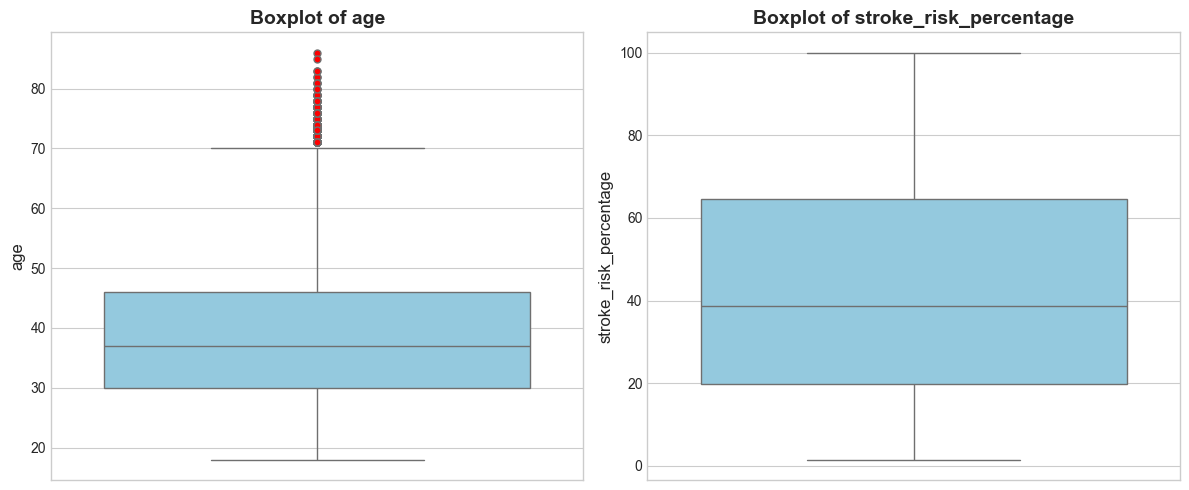


⚠️ KẾT LUẬN VỀ OUTLIER:
1. Tập dữ liệu v2 đã được làm sạch chuẩn hóa, các giá trị độ tuổi nằm trong khoảng sinh lý hợp lệ.
2. Tất cả các dữ liệu được giữ nguyên để phục vụ huấn luyện mô hình Machine Learning.


In [2]:
# ==============================================================================
# PHẦN 2: MISSING VALUES & OUTLIERS ANALYSIS (CẬP NHẬT CHO DATASET V2)
# Vị trí: Tiếp theo trong Notebook (Cell 3 & Cell 4)
# ==============================================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Tạo bản sao dataframe cho xử lý và làm sạch
df_clean = df.copy()

# ------------------------------------------------------------------------------
# 2.1. XỬ LÝ MISSING VALUES (TỰ ĐỘNG DYNAMICAL)
# ------------------------------------------------------------------------------
print("==========================================")
print("2.1. KIỂM TRA VÀ XỬ LÝ MISSING VALUES")
print("==========================================")

# Xóa cột ID nếu có
df_clean = df_clean.drop(columns=["id"], errors="ignore")

# Kiểm tra số lượng và tỷ lệ missing values trên toàn bộ dataset
missing_count = df_clean.isnull().sum()
missing_percent = (df_clean.isnull().sum() / len(df_clean)) * 100

missing_df = pd.DataFrame(
    {"Missing Count": missing_count, "Missing Ratio (%)": missing_percent}
).query("`Missing Count` > 0")

if len(missing_df) > 0:
    print("\n--- Danh sách các cột bị thiếu dữ liệu ---")
    display(missing_df)
    
    # Điền giá trị thiếu (nếu có): Median cho cột số, Mode cho cột chuỗi
    num_cols = df_clean.select_dtypes(include=[np.number]).columns
    for col in num_cols:
        if df_clean[col].isnull().sum() > 0:
            df_clean[col].fillna(df_clean[col].median(), inplace=True)
            
    cat_cols = df_clean.select_dtypes(include=['object']).columns
    for col in cat_cols:
        if df_clean[col].isnull().sum() > 0:
            df_clean[col].fillna(df_clean[col].mode()[0], inplace=True)
    print("✅ Đã tự động xử lý toàn bộ giá trị bị thiếu (Missing Values).")
else:
    print("✅ Dataset v2 hoàn toàn không có giá trị bị thiếu (No Missing Values).")


# ------------------------------------------------------------------------------
# 2.2. PHÂN TÍCH VÀ KIỂM TRA OUTLIERS (IQR METHOD)
# ------------------------------------------------------------------------------
print("\n==========================================")
print("2.2. KIỂM TRA OUTLIERS CHO CÁC BIẾN SỐ LIÊN TỤC")
print("==========================================")

# Hàm tính toán số lượng outlier theo phương pháp IQR
def detect_outliers_iqr(dataframe, features):
    outlier_summary = []

    for col in features:
        Q1 = dataframe[col].quantile(0.25)
        Q3 = dataframe[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = dataframe[
            (dataframe[col] < lower_bound) | (dataframe[col] > upper_bound)
        ]
        outlier_count = len(outliers)
        outlier_ratio = (outlier_count / len(dataframe)) * 100

        outlier_summary.append(
            {
                "Feature": col,
                "Q1 (25%)": round(Q1, 2),
                "Q3 (75%)": round(Q3, 2),
                "IQR": round(IQR, 2),
                "Lower Bound": round(lower_bound, 2),
                "Upper Bound": round(upper_bound, 2),
                "Outlier Count": outlier_count,
                "Outlier Ratio (%)": round(outlier_ratio, 2),
            }
        )

    return pd.DataFrame(outlier_summary)


# Lọc danh sách các biến số liên tục (có nhiều hơn 2 giá trị độc lập, loại bỏ biến nhị phân 0/1)
continuous_features = [
    col for col in df_clean.select_dtypes(include=[np.number]).columns 
    if df_clean[col].nunique() > 2 and col not in ['at_risk', 'stroke']
]

print(f"Các biến số liên tục được kiểm tra Outliers: {continuous_features}")

if len(continuous_features) > 0:
    outlier_df = detect_outliers_iqr(df_clean, continuous_features)

    print("\n--- BẢNG THỐNG KÊ OUTLIERS THEO IQR ---")
    display(outlier_df)

    # ------------------------------------------------------------------------------
    # 2.3. TRỰC QUAN HÓA OUTLIERS BẰNG BOXPLOT
    # ------------------------------------------------------------------------------
    num_plots = len(continuous_features)
    fig, axes = plt.subplots(1, num_plots, figsize=(6 * num_plots, 5))
    
    if num_plots == 1:
        axes = [axes]

    for i, col in enumerate(continuous_features):
        sns.boxplot(
            y=df_clean[col], 
            ax=axes[i], 
            color="skyblue", 
            flierprops={"markerfacecolor": "red", "markersize": 5}
        )
        axes[i].set_title(f"Boxplot of {col}", fontsize=14, fontweight="bold")
        axes[i].set_ylabel(col, fontsize=12)

    plt.tight_layout()
    plt.show()

print("\n⚠️ KẾT LUẬN VỀ OUTLIER:")
print("1. Tập dữ liệu v2 đã được làm sạch chuẩn hóa, các giá trị độ tuổi nằm trong khoảng sinh lý hợp lệ.")
print("2. Tất cả các dữ liệu được giữ nguyên để phục vụ huấn luyện mô hình Machine Learning.")

3.1. PHÂN TÍCH PHÂN BỐ NHÃN TARGET ('AT_RISK')
Số lượng at_risk = 0 (Không nguy cơ): 22113
Số lượng at_risk = 1 (Có nguy cơ)   : 12887
Tỷ lệ at_risk = 0                   : 63.18%
Tỷ lệ at_risk = 1                   : 36.82%


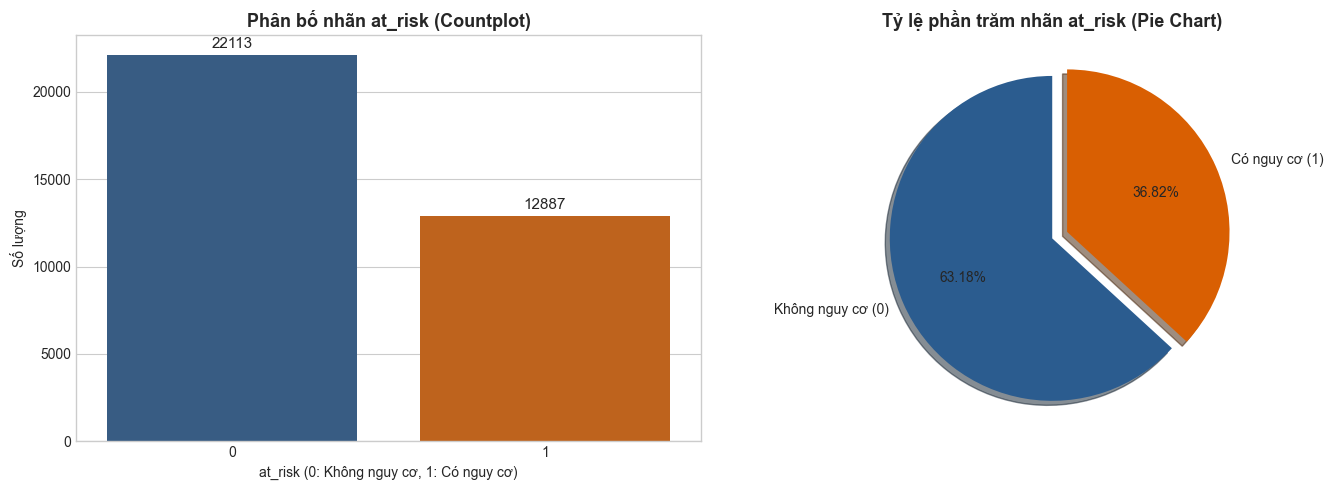


3.2. TRỰC QUAN HÓA CHI TIẾT CÁC ĐẶC TRƯNG


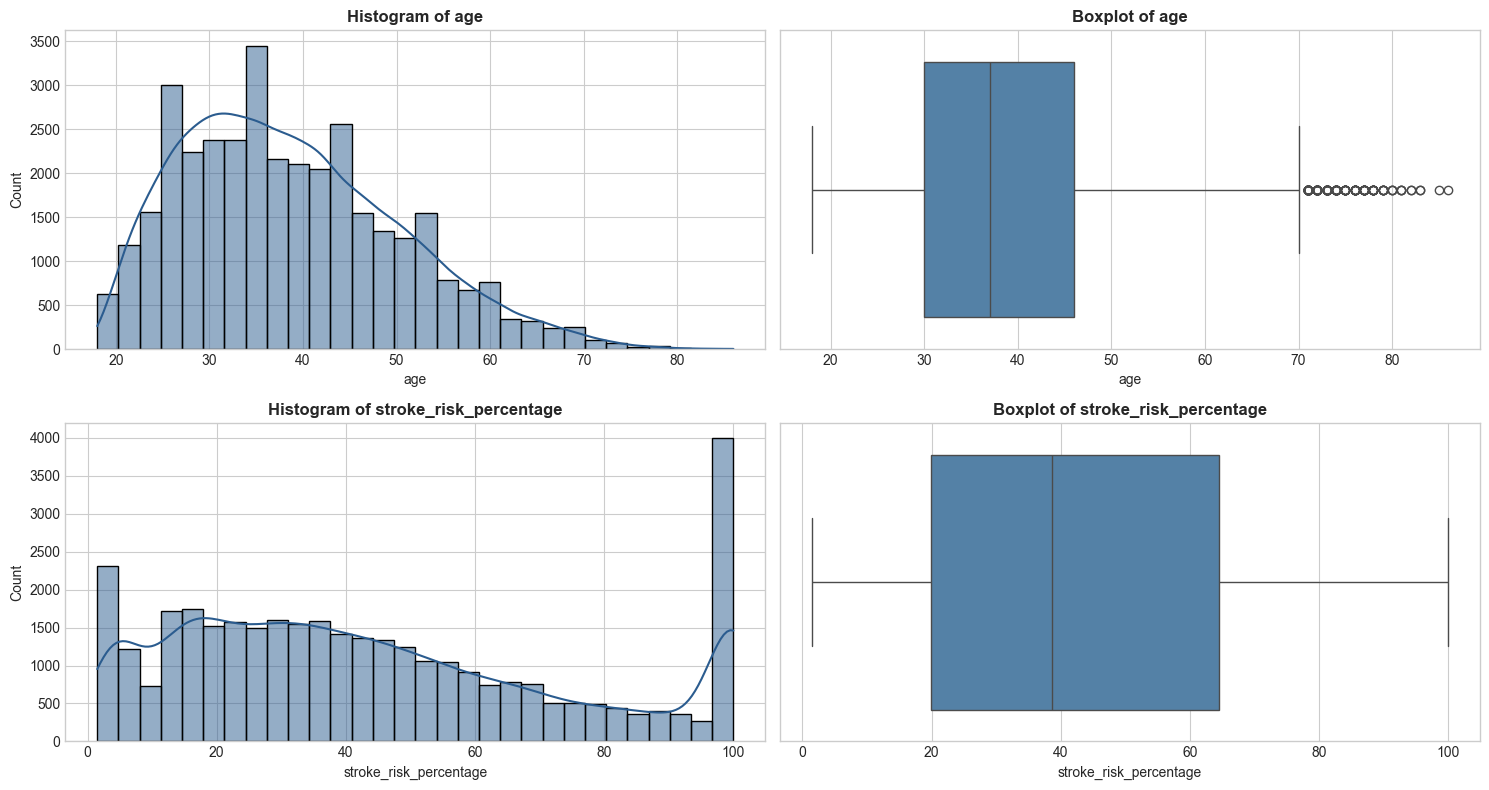

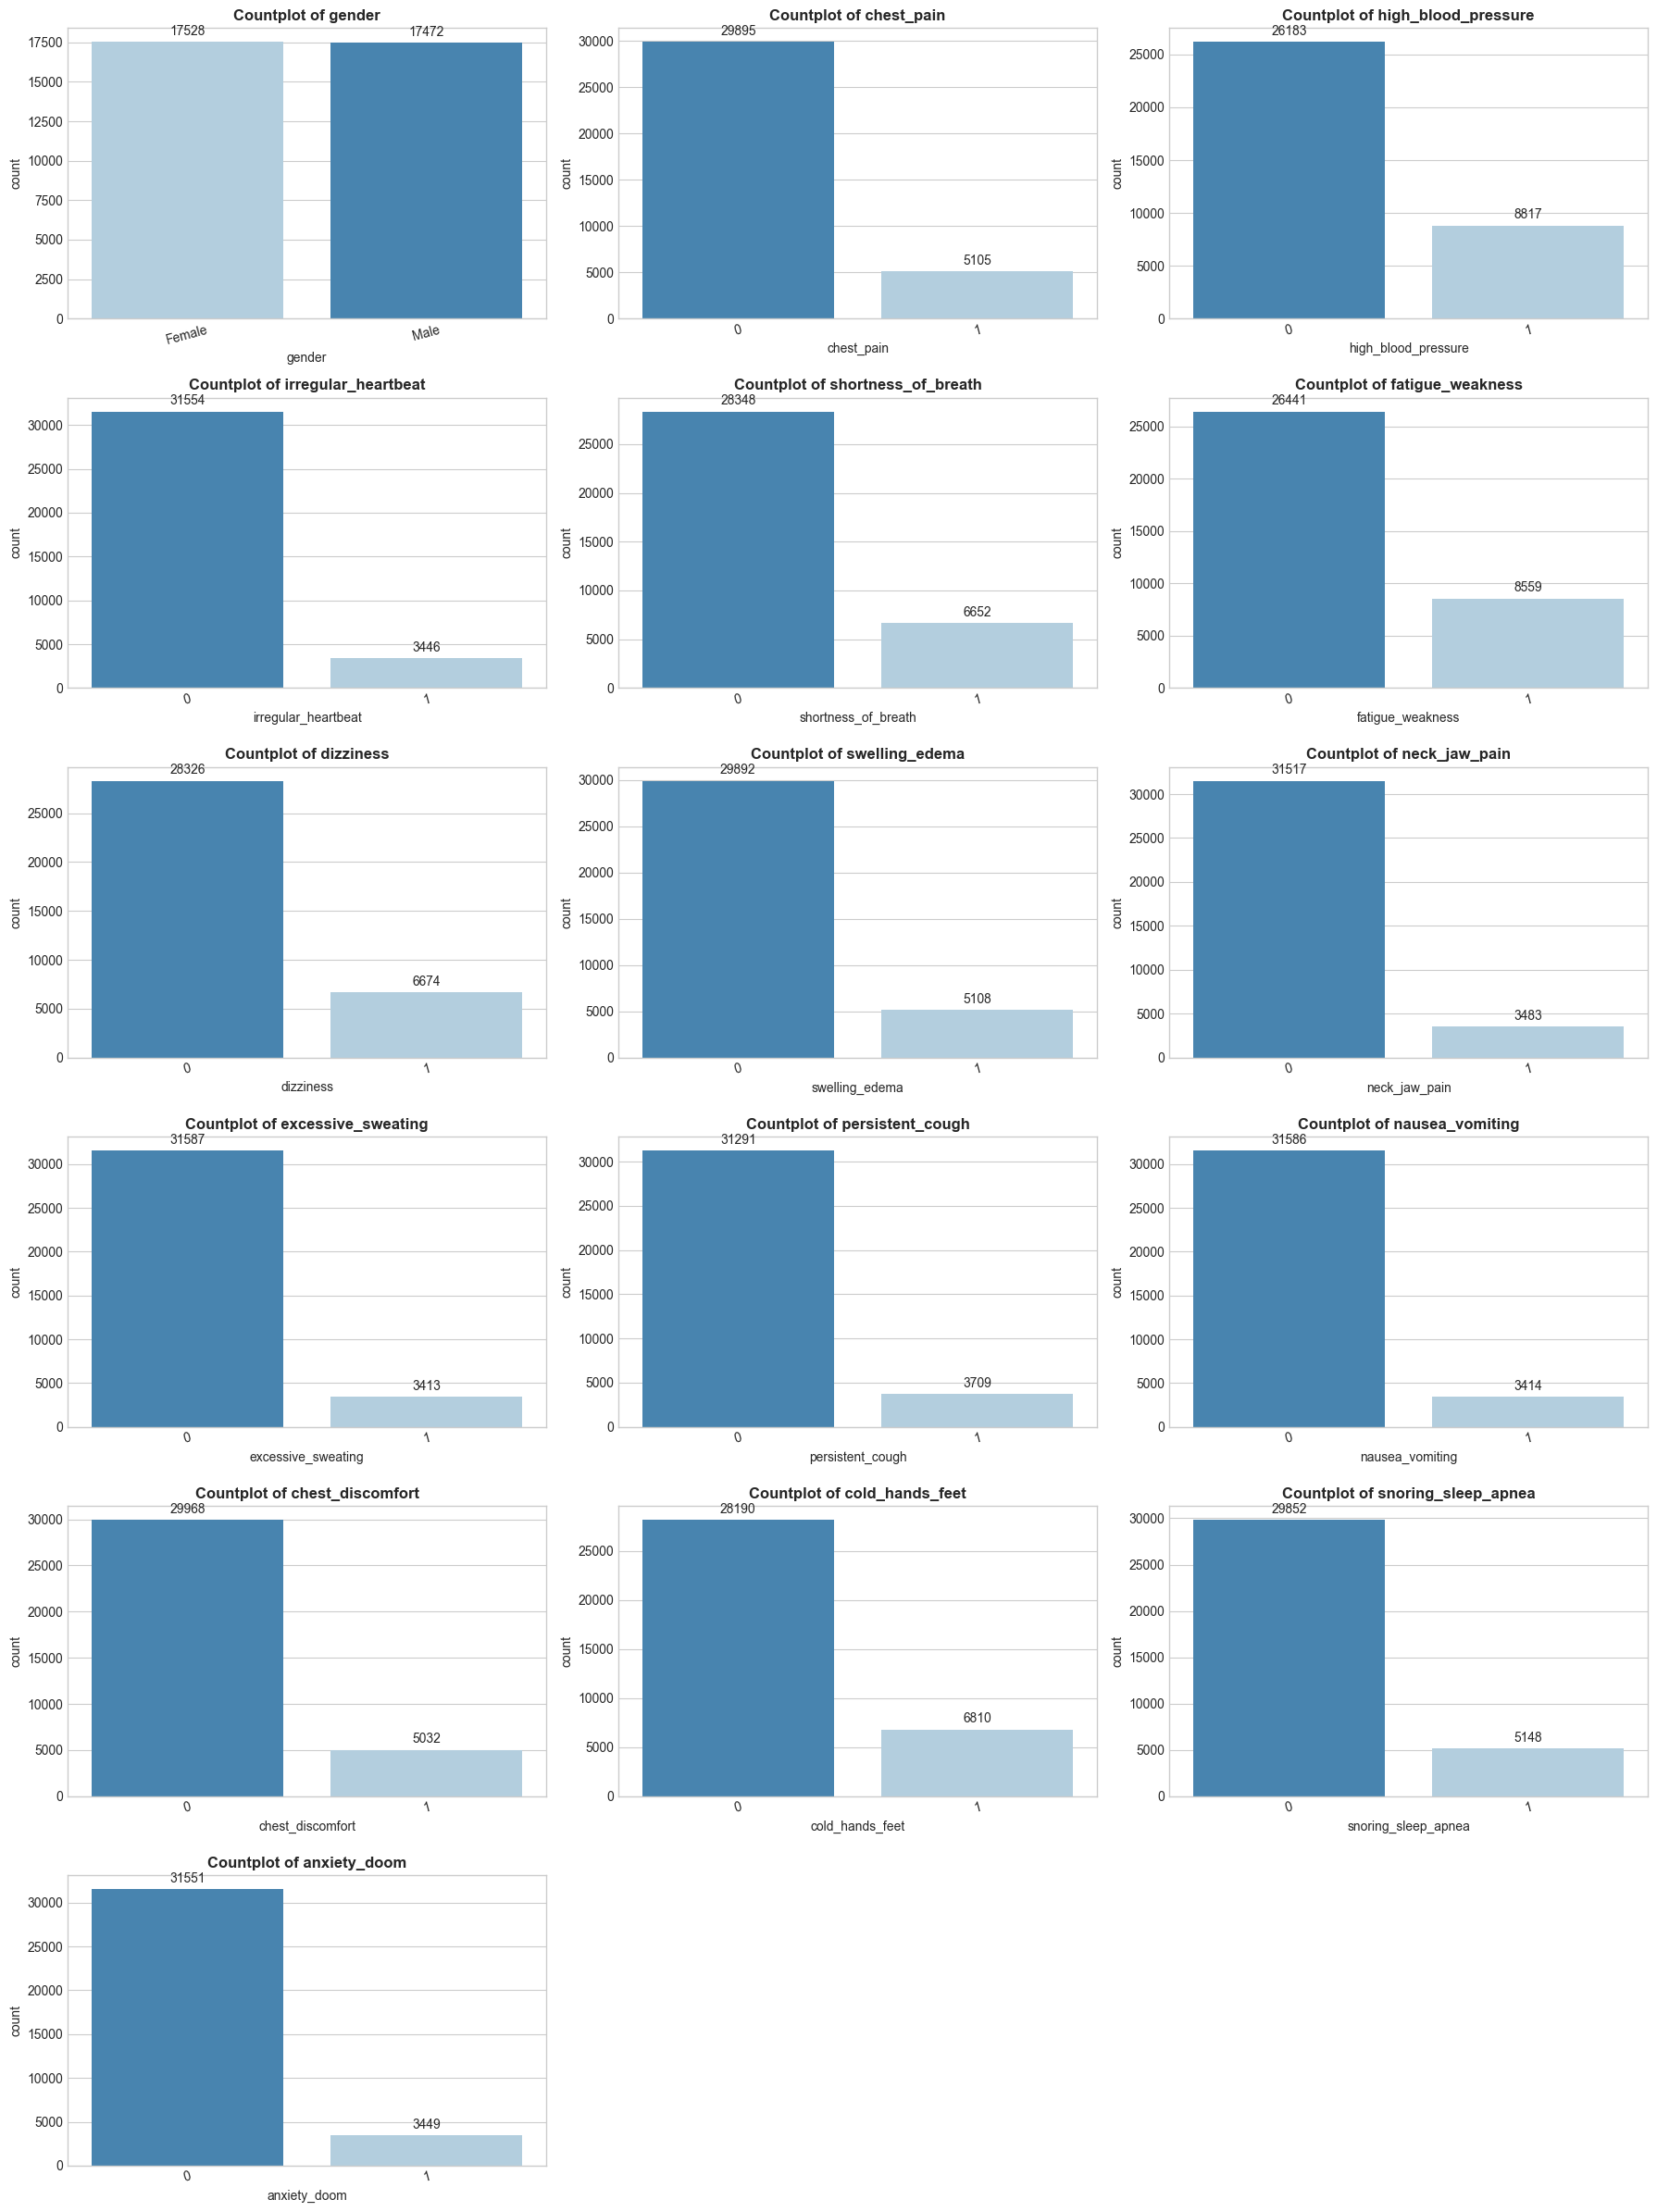


3.3. SO SÁNH CÁC BIẾN ĐẦU VÀO VỚI 'AT_RISK'


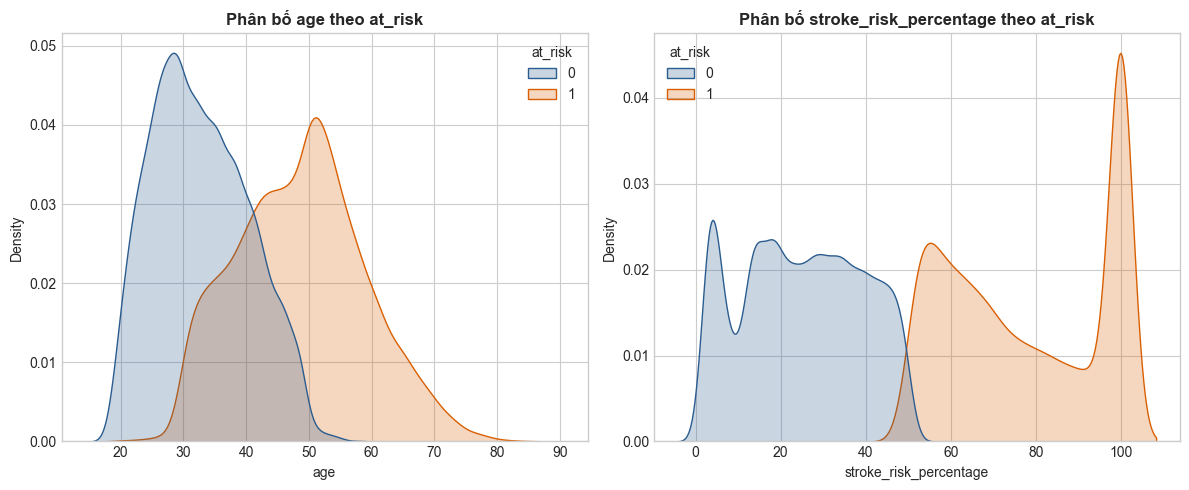

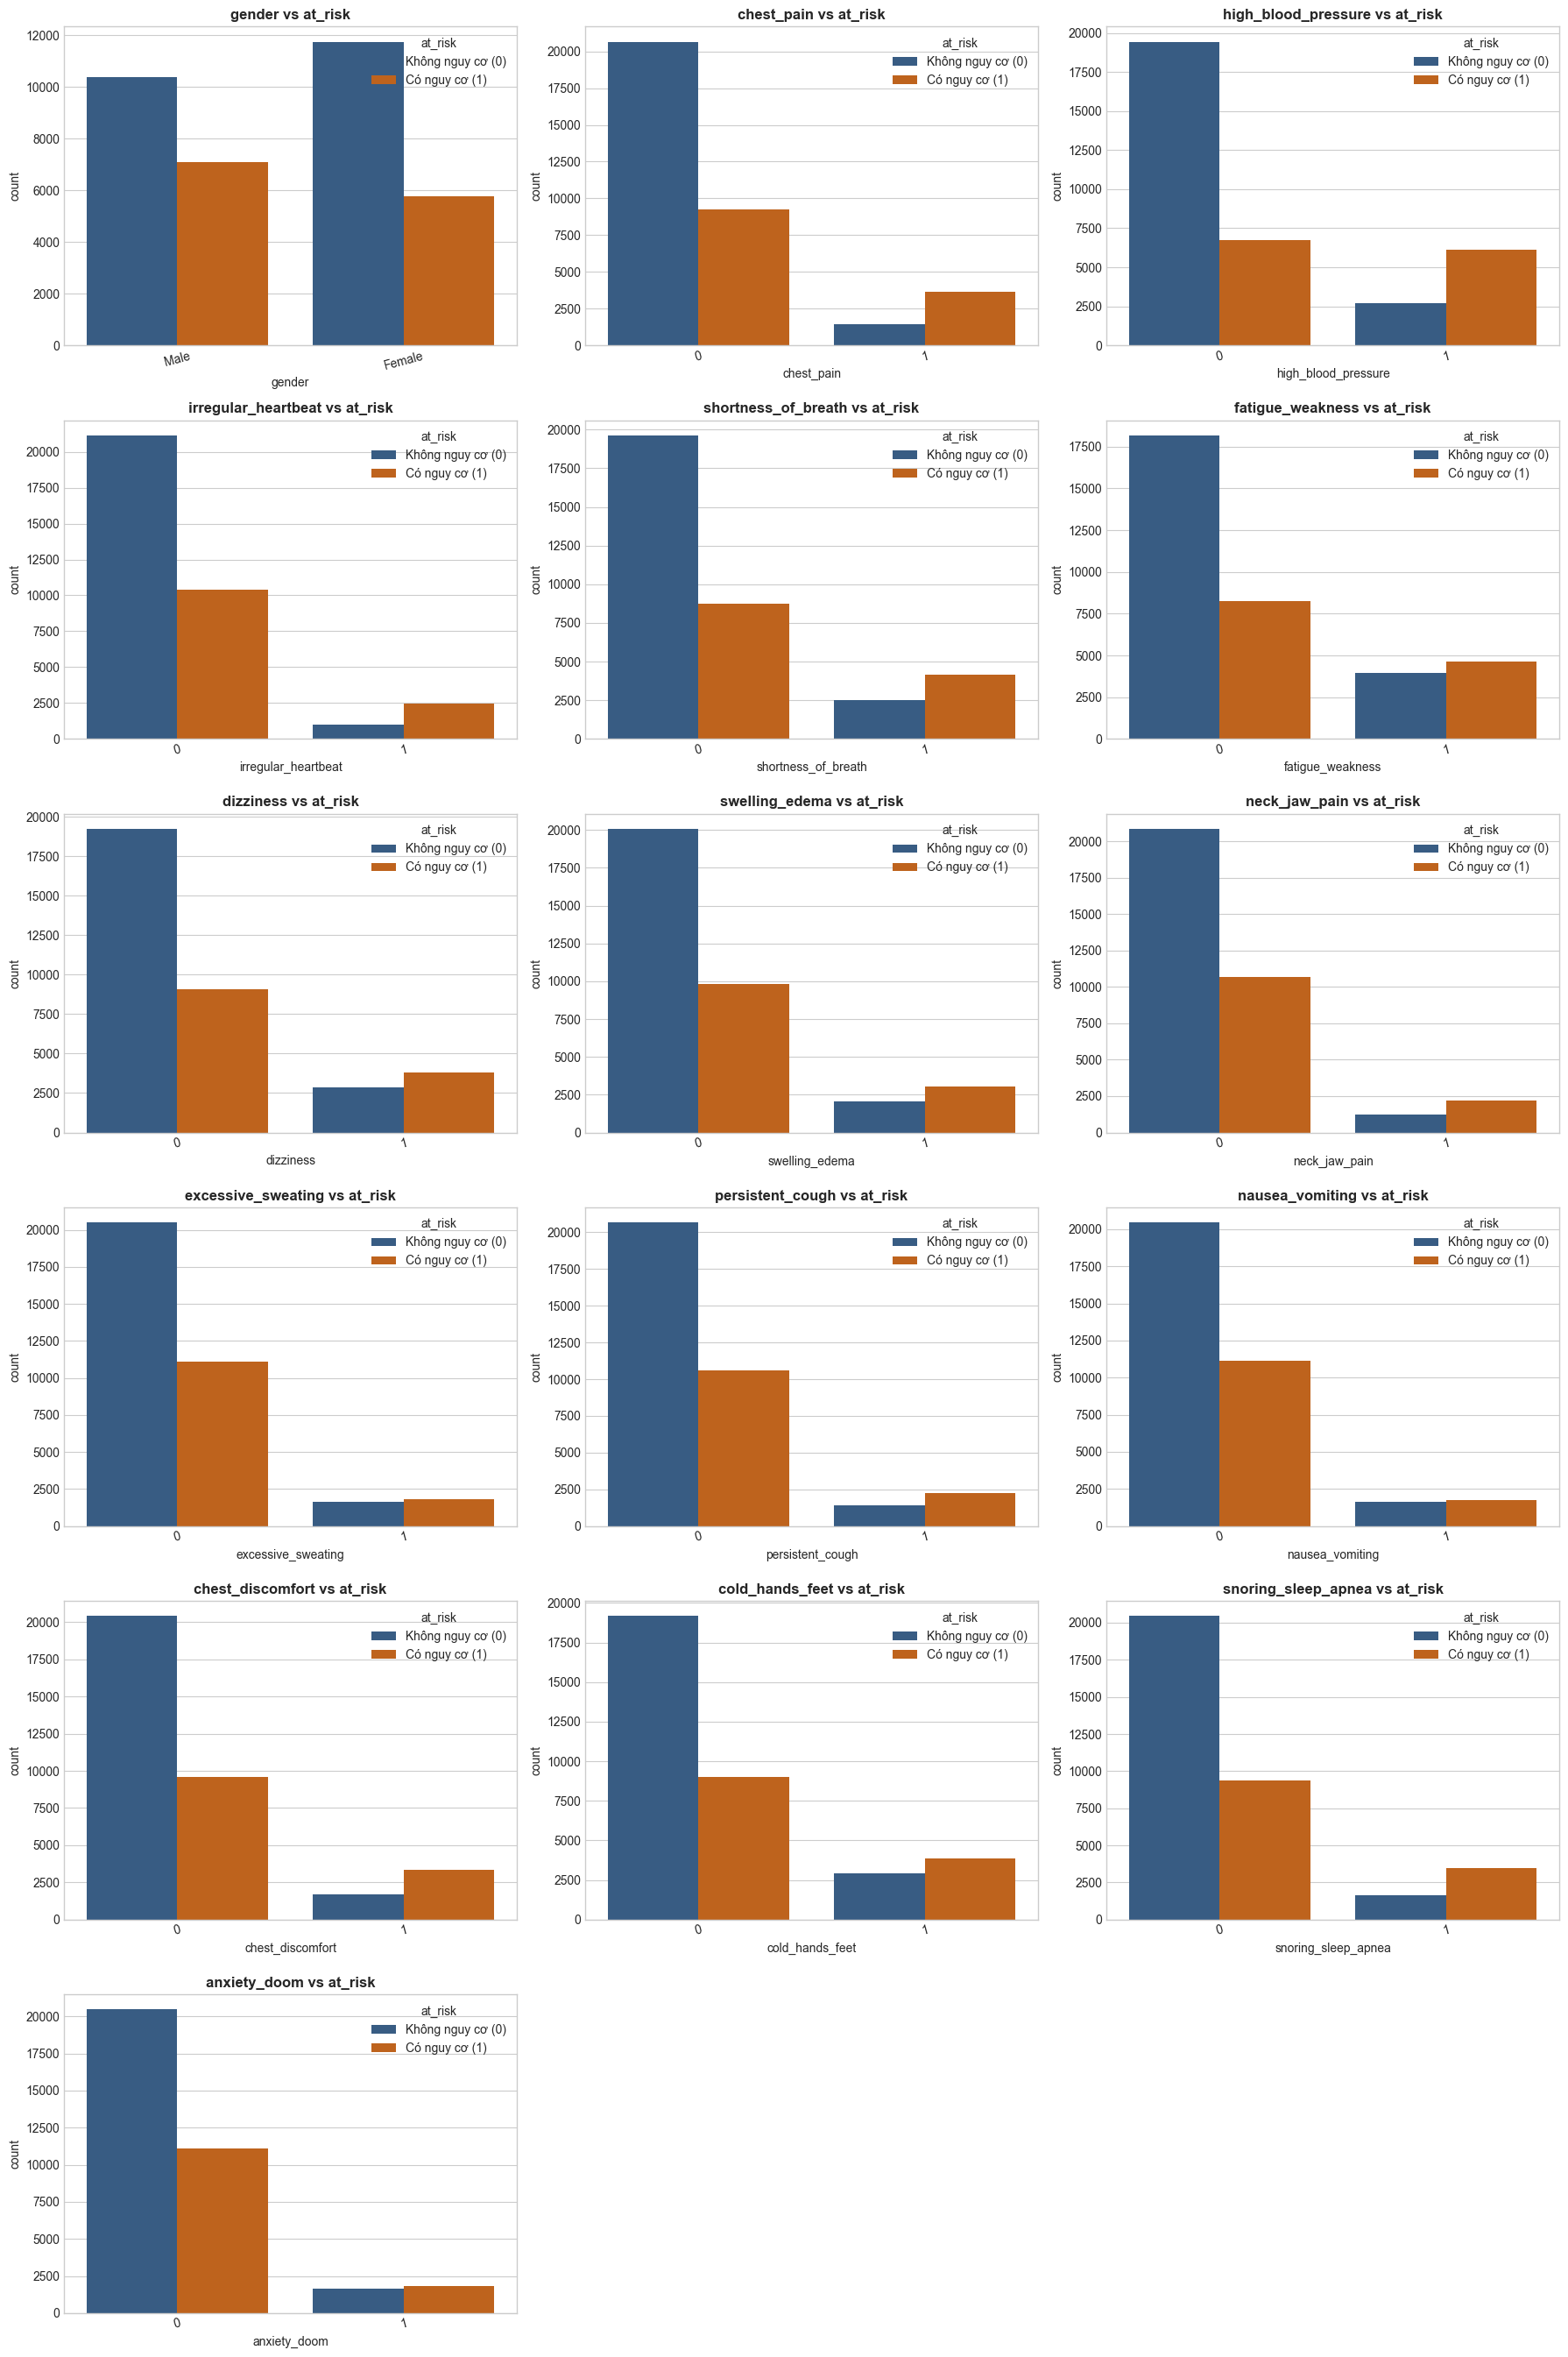

In [3]:
# ==============================================================================
# PHẦN 3: TRỰC QUAN HÓA DỮ LIỆU (VISUALIZATION & CLASS DISTRIBUTION)
# Vị trí: Cell tiếp theo trong Notebook (Đã tự động hóa cho Dataset V2)
# ==============================================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set màu chuẩn cho đồ thị
palette = ["#2b5c8f", "#d95f02"]

# Tự động xác định tên cột Target
target_col = 'at_risk' if 'at_risk' in df_clean.columns else ('stroke' if 'stroke' in df_clean.columns else df_clean.columns[-1])

# ------------------------------------------------------------------------------
# 3.1. PHÂN TÍCH VÀ TRỰC QUAN HÓA PHÂN BỐ NHÃN (CLASS IMBALANCE)
# ------------------------------------------------------------------------------
print("==========================================")
print(f"3.1. PHÂN TÍCH PHÂN BỐ NHÃN TARGET ('{target_col.upper()}')")
print("==========================================")

stroke_counts = df_clean[target_col].value_counts()
stroke_percentages = df_clean[target_col].value_counts(normalize=True) * 100

val_0 = stroke_counts.get(0, 0)
val_1 = stroke_counts.get(1, 0)
pct_0 = stroke_percentages.get(0, 0.0)
pct_1 = stroke_percentages.get(1, 0.0)

print(f"Số lượng {target_col} = 0 (Không nguy cơ): {val_0}")
print(f"Số lượng {target_col} = 1 (Có nguy cơ)   : {val_1}")
print(f"Tỷ lệ {target_col} = 0                   : {pct_0:.2f}%")
print(f"Tỷ lệ {target_col} = 1                   : {pct_1:.2f}%")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ cột (Countplot)
sns.countplot(x=target_col, data=df_clean, ax=ax[0], hue=target_col, palette=palette, legend=False)
ax[0].set_title(f"Phân bố nhãn {target_col} (Countplot)", fontsize=13, fontweight="bold")
ax[0].set_xlabel(f"{target_col} (0: Không nguy cơ, 1: Có nguy cơ)")
ax[0].set_ylabel("Số lượng")

for p in ax[0].patches:
    height = p.get_height()
    if height > 0:
        ax[0].annotate(
            f"{int(height)}",
            (p.get_x() + p.get_width() / 2.0, height),
            ha="center",
            va="bottom",
            fontsize=11,
            xytext=(0, 3),
            textcoords="offset points",
        )

# Biểu đồ tròn (Pie chart)
ax[1].pie(
    [val_0, val_1],
    labels=["Không nguy cơ (0)", "Có nguy cơ (1)"],
    colors=palette,
    autopct="%1.2f%%",
    explode=[0, 0.1],
    startangle=90,
    shadow=True,
)
ax[1].set_title(f"Tỷ lệ phần trăm nhãn {target_col} (Pie Chart)", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------------------------
# 3.2. TRỰC QUAN HÓA CÁC ĐẶC TRƯNG CHÍNH (SINGLE FEATURES DISTRIBUTION)
# ------------------------------------------------------------------------------
print("\n==========================================")
print("3.2. TRỰC QUAN HÓA CHI TIẾT CÁC ĐẶC TRƯNG")
print("==========================================")

# Phân loại tự động biến số liên tục và biến phân loại/nhị phân
num_cols = [
    col for col in df_clean.select_dtypes(include=[np.number]).columns 
    if df_clean[col].nunique() > 5 and col != target_col
]

cat_cols = [
    col for col in df_clean.columns 
    if (df_clean[col].nunique() <= 5 or df_clean[col].dtype == 'object') and col != target_col
]

# A. Trực quan biến định lượng liên tục (Histogram & Boxplot)
if len(num_cols) > 0:
    fig, axes = plt.subplots(len(num_cols), 2, figsize=(15, 4 * len(num_cols)))
    if len(num_cols) == 1:
        axes = np.expand_dims(axes, axis=0)

    for i, col in enumerate(num_cols):
        # Histogram
        sns.histplot(df_clean[col], kde=True, ax=axes[i, 0], color="#2b5c8f", bins=30)
        axes[i, 0].set_title(f"Histogram of {col}", fontsize=12, fontweight="bold")

        # Boxplot
        sns.boxplot(x=df_clean[col], ax=axes[i, 1], color="#4682b4")
        axes[i, 1].set_title(f"Boxplot of {col}", fontsize=12, fontweight="bold")

    plt.tight_layout()
    plt.show()

# B. Trực quan biến định tính / phân loại (Countplot)
if len(cat_cols) > 0:
    n_cats = len(cat_cols)
    n_cols_plot = 3
    n_rows_plot = (n_cats + n_cols_plot - 1) // n_cols_plot

    fig, axes = plt.subplots(n_rows_plot, n_cols_plot, figsize=(18, 4 * n_rows_plot))
    axes = axes.flatten() if n_cats > 1 else [axes]

    for i, col in enumerate(cat_cols):
        sns.countplot(
            x=col,
            data=df_clean,
            ax=axes[i],
            hue=col,
            palette="Blues_r",
            legend=False,
            order=df_clean[col].value_counts().index,
        )
        axes[i].set_title(f"Countplot of {col}", fontsize=12, fontweight="bold")
        axes[i].tick_params(axis="x", rotation=15)
        for p in axes[i].patches:
            h = p.get_height()
            if h > 0:
                axes[i].annotate(
                    f"{int(h)}",
                    (p.get_x() + p.get_width() / 2.0, h),
                    ha="center",
                    va="bottom",
                    xytext=(0, 3),
                    textcoords="offset points",
                )

    # Ẩn các khung hình thừa nếu số lượng biểu đồ không chia hết cho 3
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------------------------
# 3.3. SO SÁNH CÁC BIẾN ĐẦU VÀO VỚI TARGET
# ------------------------------------------------------------------------------
print("\n==========================================")
print(f"3.3. SO SÁNH CÁC BIẾN ĐẦU VÀO VỚI '{target_col.upper()}'")
print("==========================================")

# A. Biến số so sánh với Target
if len(num_cols) > 0:
    fig, axes = plt.subplots(1, len(num_cols), figsize=(6 * len(num_cols), 5))
    if len(num_cols) == 1:
        axes = [axes]

    for i, col in enumerate(num_cols):
        sns.kdeplot(
            data=df_clean,
            x=col,
            hue=target_col,
            common_norm=False,
            palette=palette,
            ax=axes[i],
            fill=True,
        )
        axes[i].set_title(f"Phân bố {col} theo {target_col}", fontsize=12, fontweight="bold")

    plt.tight_layout()
    plt.show()

# B. Biến phân loại so sánh với Target
if len(cat_cols) > 0:
    n_cats = len(cat_cols)
    n_cols_plot = 3
    n_rows_plot = (n_cats + n_cols_plot - 1) // n_cols_plot

    fig, axes = plt.subplots(n_rows_plot, n_cols_plot, figsize=(18, 4.5 * n_rows_plot))
    axes = axes.flatten() if n_cats > 1 else [axes]

    for i, col in enumerate(cat_cols):
        sns.countplot(
            x=col,
            hue=target_col,
            data=df_clean,
            ax=axes[i],
            palette=palette,
        )
        axes[i].set_title(f"{col} vs {target_col}", fontsize=12, fontweight="bold")
        axes[i].tick_params(axis="x", rotation=15)
        axes[i].legend(title=target_col, labels=["Không nguy cơ (0)", "Có nguy cơ (1)"], loc="upper right")

    # Ẩn các khung hình thừa
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

✅ Đang sử dụng cột target: 'at_risk'
✅ Kích thước dữ liệu: (35000, 19)
✅ Số lượng cột: 19

4.1. TRỰC QUAN HÓA CORRELATION MATRIX
Các cột số dùng để tính tương quan: ['age', 'chest_pain', 'high_blood_pressure', 'irregular_heartbeat', 'shortness_of_breath', 'fatigue_weakness', 'dizziness', 'swelling_edema', 'neck_jaw_pain', 'excessive_sweating', 'persistent_cough', 'nausea_vomiting', 'chest_discomfort', 'cold_hands_feet', 'snoring_sleep_apnea', 'anxiety_doom', 'stroke_risk_percentage', 'at_risk']


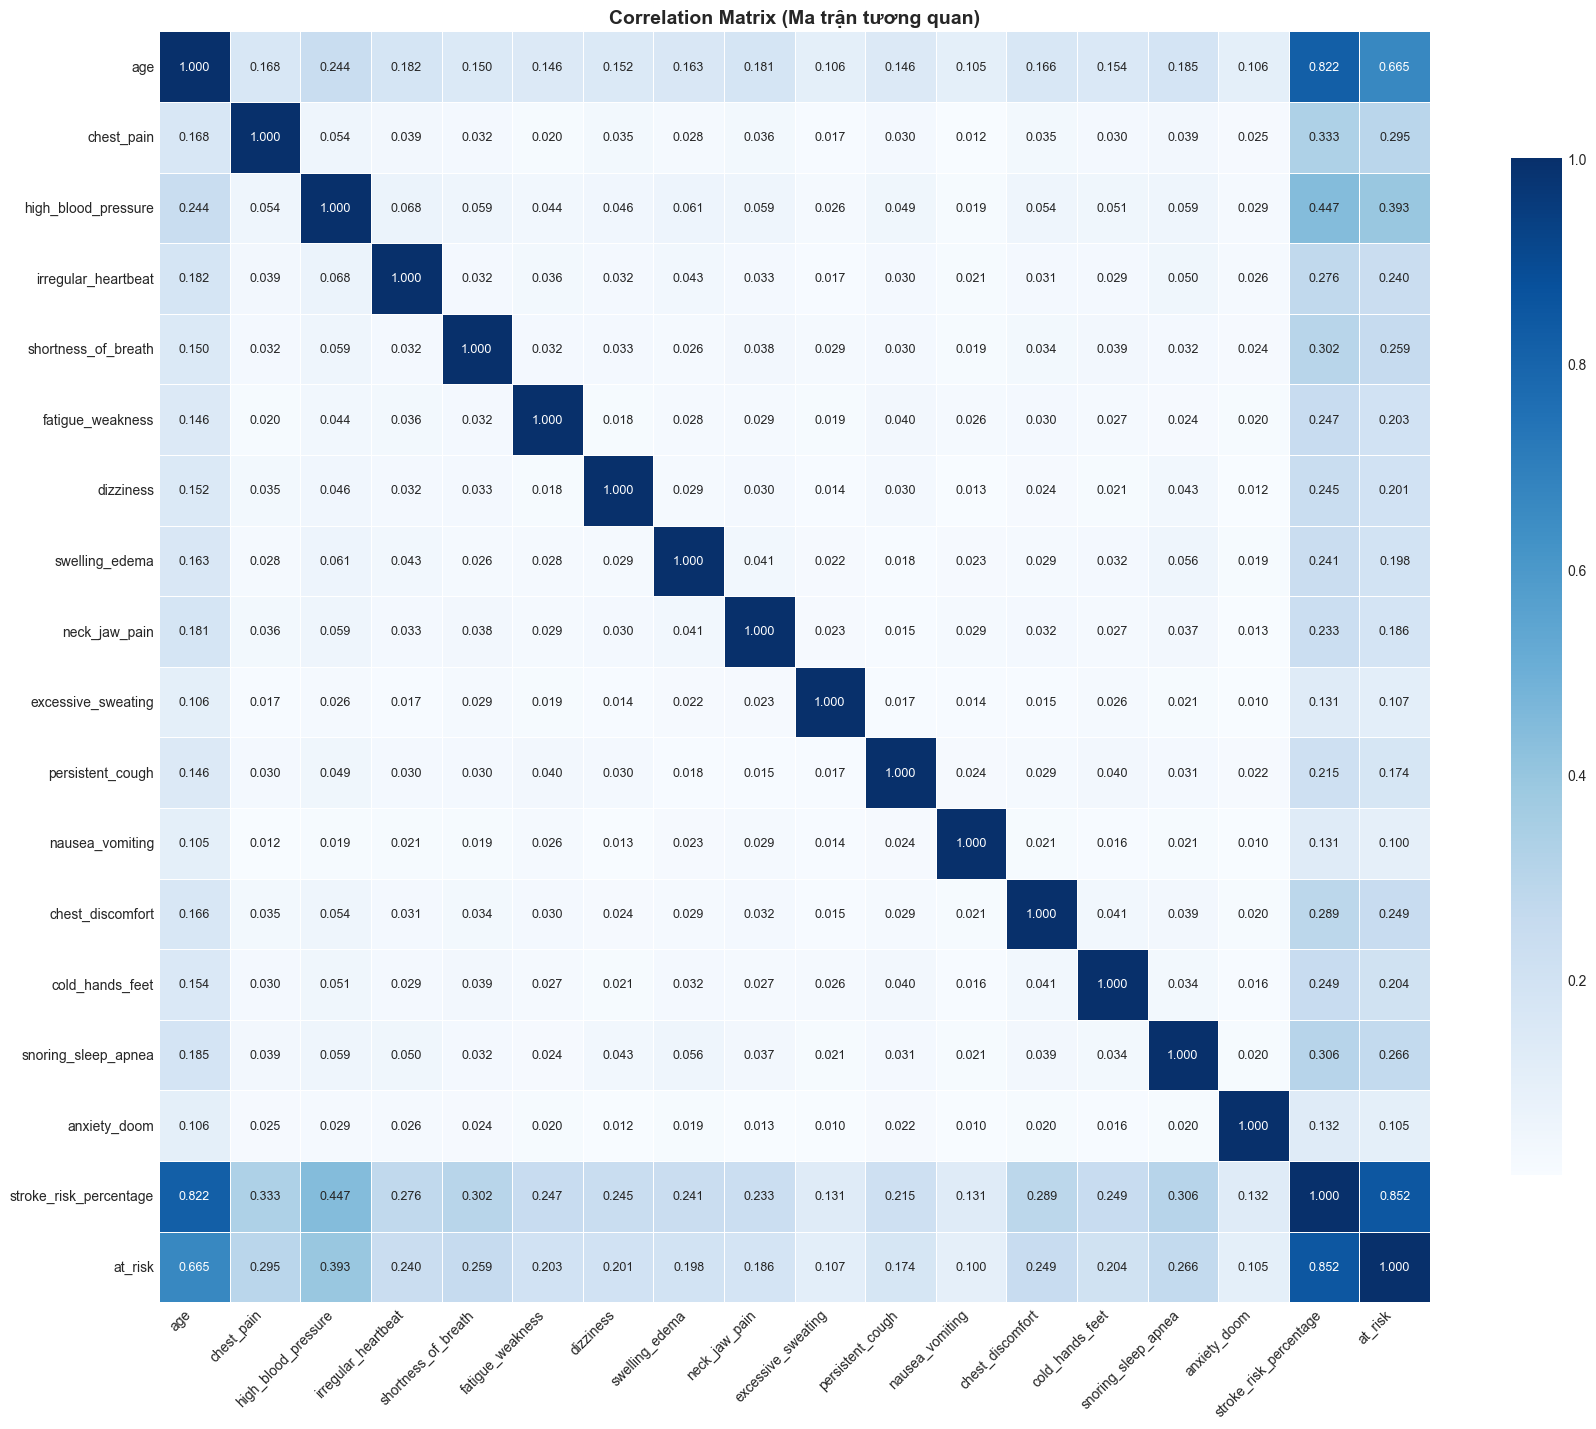


--- Nhận xét tương quan với biến target 'at_risk' ---
                        Hệ số tương quan
at_risk                         1.000000
stroke_risk_percentage          0.852185
age                             0.664524
high_blood_pressure             0.393487
chest_pain                      0.295271
snoring_sleep_apnea             0.266177
shortness_of_breath             0.258746
chest_discomfort                0.248903
irregular_heartbeat             0.239826
cold_hands_feet                 0.204342
fatigue_weakness                0.202815
dizziness                       0.200802
swelling_edema                  0.198199
neck_jaw_pain                   0.186125
persistent_cough                0.173854
excessive_sweating              0.107098
anxiety_doom                    0.104957
nausea_vomiting                 0.100022

4.2. TÍNH FEATURE IMPORTANCE TỪ TREE-BASED MODELS
Đang mã hóa 1 cột phân loại: ['gender']
Kích thước X sau xử lý: (35000, 18)
Kích thước y: (35000,)
  → Đang huấn lu

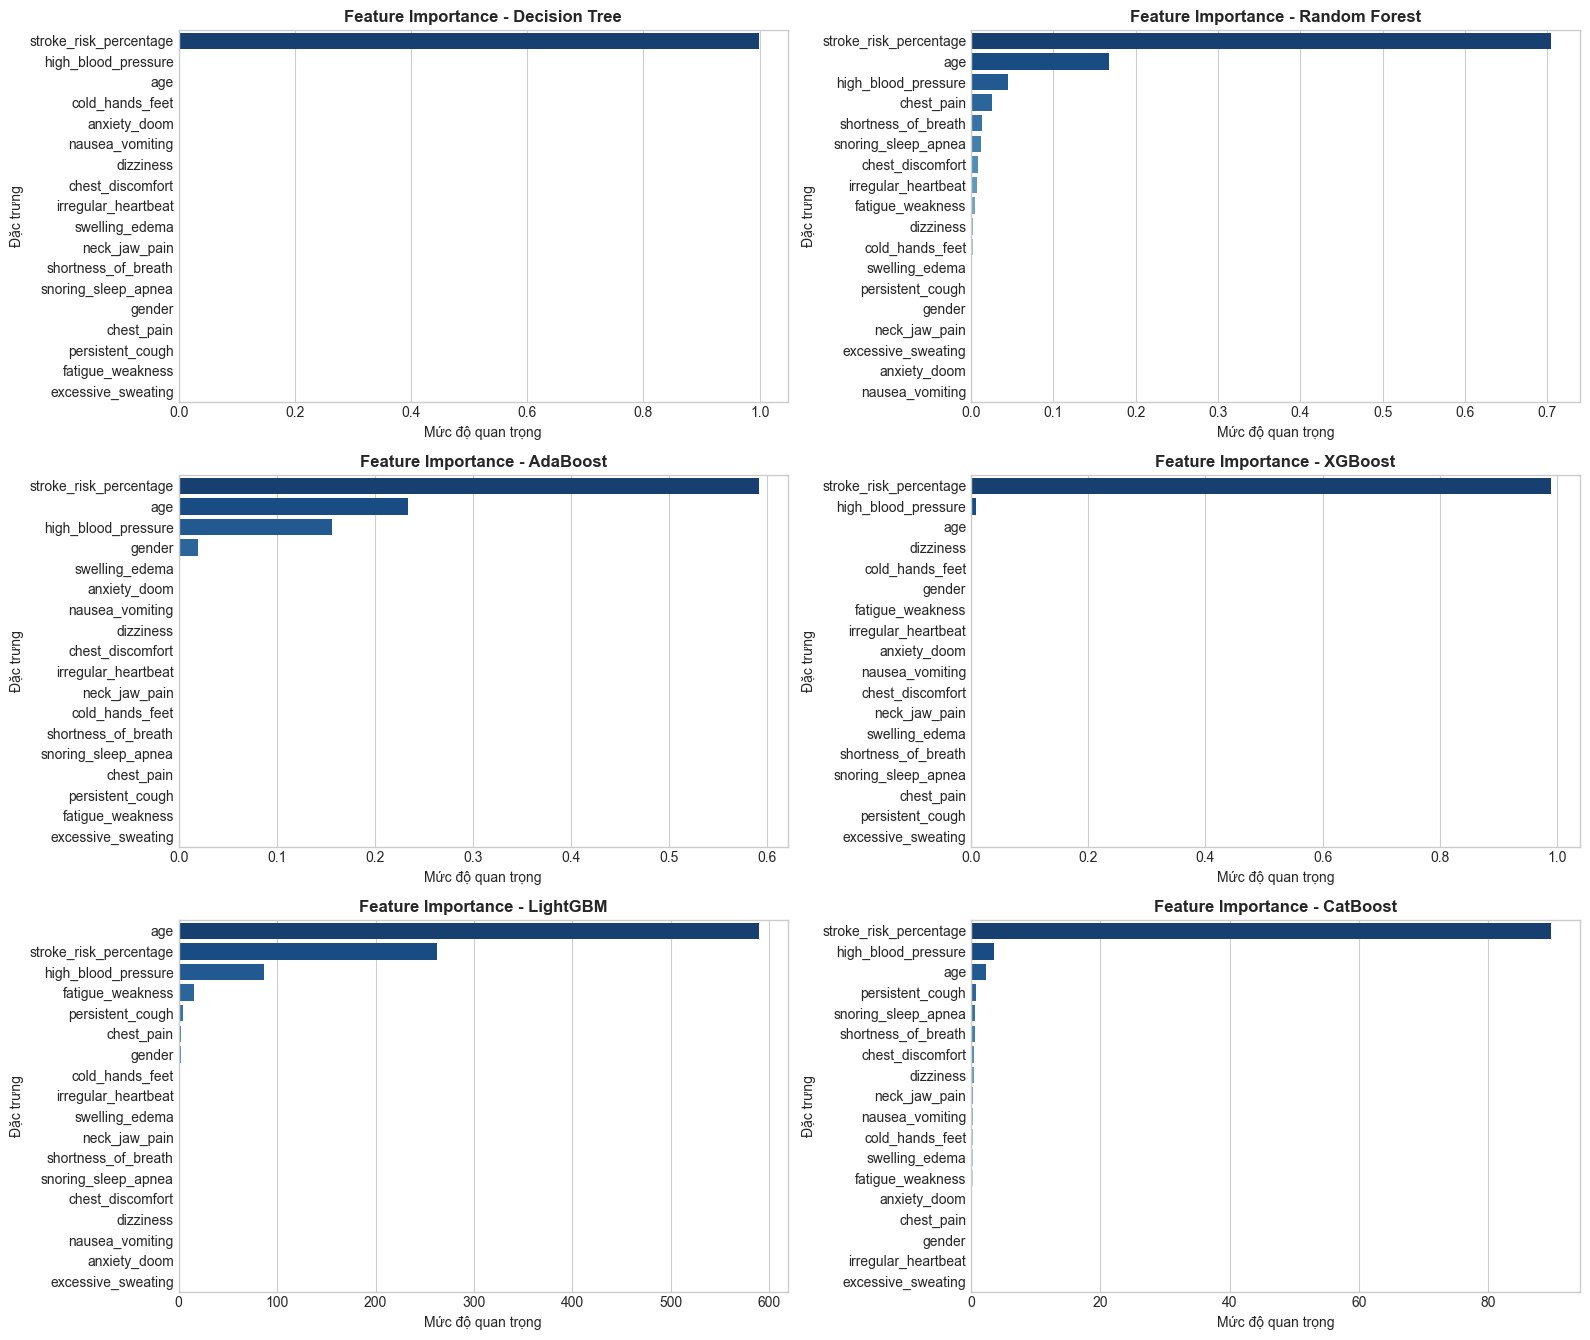


4.4. TRUNG BÌNH FEATURE IMPORTANCE QUA CÁC MÔ HÌNH


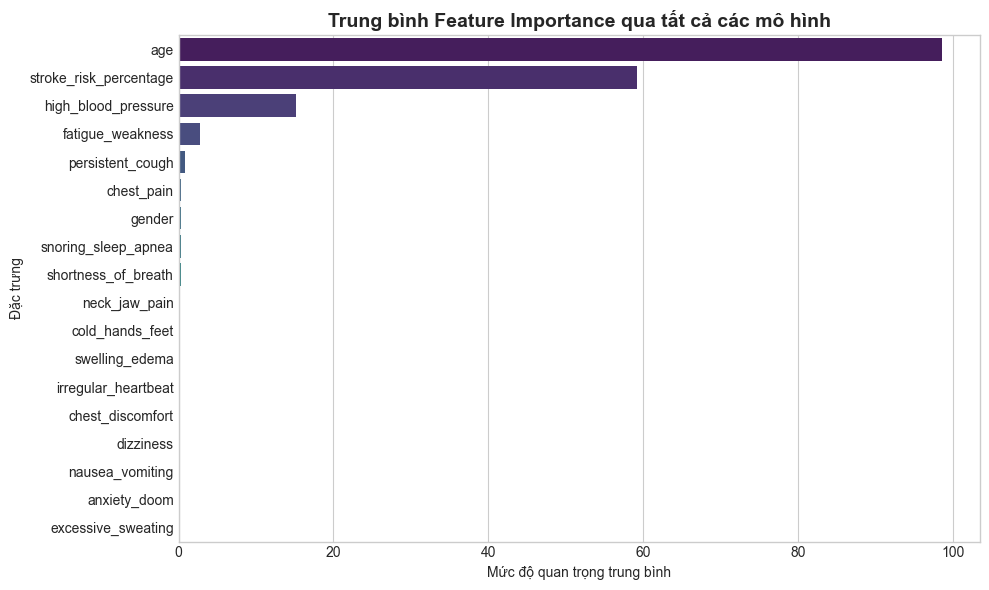


--- TOP 5 ĐẶC TRƯNG QUAN TRỌNG NHẤT ---
  1. age                       : 98.6126
  18. stroke_risk_percentage    : 59.1632
  4. high_blood_pressure       : 15.1276
  7. fatigue_weakness          : 2.7072
  12. persistent_cough          : 0.7984


In [4]:
# ==============================================================================
# PHẦN 4: CORRELATION MATRIX & FEATURE IMPORTANCE (AUTO-DETECT TARGET V2)
# Vị trí: Cell tiếp theo trong Notebook
# ==============================================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import (
    AdaBoostClassifier,
    RandomForestClassifier,
)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# Kiểm tra thư viện nâng cao (LightGBM & CatBoost)
try:
    from lightgbm import LGBMClassifier
except ImportError:
    LGBMClassifier = None

try:
    from catboost import CatBoostClassifier
except ImportError:
    CatBoostClassifier = None

# ------------------------------------------------------------------------------
# 0. TỰ ĐỘNG XÁC ĐỊNH TARGET VÀ DỮ LIỆU ĐẦU VÀO
# ------------------------------------------------------------------------------
# Ưu tiên dùng df_clean nếu đã tạo ở Phần 3, nếu không thì dùng df
target_df = df_clean if "df_clean" in globals() else df

# Tự động tìm cột target (at_risk, stroke, hoặc cột cuối cùng)
if "at_risk" in target_df.columns:
    TARGET_COL = "at_risk"
elif "stroke" in target_df.columns:
    TARGET_COL = "stroke"
else:
    TARGET_COL = target_df.columns[-1]

print(f"✅ Đang sử dụng cột target: '{TARGET_COL}'")
print(f"✅ Kích thước dữ liệu: {target_df.shape}")
print(f"✅ Số lượng cột: {len(target_df.columns)}")

# ------------------------------------------------------------------------------
# 4.1. CORRELATION MATRIX (MA TRẬN TƯƠNG QUAN) - TỰ ĐỘNG CHỌN CỘT SỐ
# ------------------------------------------------------------------------------
print("\n==========================================")
print("4.1. TRỰC QUAN HÓA CORRELATION MATRIX")
print("==========================================")

# Tự động chọn các cột số (loại bỏ cột id và target)
numeric_cols = target_df.select_dtypes(include=[np.number]).columns.tolist()
numeric_cols = [c for c in numeric_cols if c.lower() not in ["id", "unnamed: 0"]]

# Đảm bảo target nằm trong danh sách để tính tương quan
if TARGET_COL not in numeric_cols:
    numeric_cols.append(TARGET_COL)

# Loại bỏ các cột có quá ít giá trị unique (ví dụ cột hằng số) trừ target
corr_features = [
    c for c in numeric_cols
    if target_df[c].nunique() > 1 or c == TARGET_COL
]

print(f"Các cột số dùng để tính tương quan: {corr_features}")

# Tính ma trận tương quan (bỏ NaN khi tính)
corr_matrix = target_df[corr_features].corr()

# Vẽ Heatmap
plt.figure(figsize=(max(8, len(corr_features)), max(6, len(corr_features) * 0.8)))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    annot_kws={"size": 9},
)
plt.title(
    "Correlation Matrix (Ma trận tương quan)", fontsize=14, fontweight="bold"
)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print(f"\n--- Nhận xét tương quan với biến target '{TARGET_COL}' ---")
print(
    corr_matrix[TARGET_COL]
    .sort_values(ascending=False)
    .to_frame(name="Hệ số tương quan")
)


# ------------------------------------------------------------------------------
# 4.2. FEATURE IMPORTANCE TỪ CÁC MODEL DẠNG CÂY (TREE-BASED MODELS)
# ------------------------------------------------------------------------------
print("\n==========================================")
print("4.2. TÍNH FEATURE IMPORTANCE TỪ TREE-BASED MODELS")
print("==========================================")

# Chuẩn bị dữ liệu
df_tree = target_df.drop(columns=["id", "Unnamed: 0"], errors="ignore").copy()

# Loại bỏ các cột không phải số và không phải target nếu cần (giữ lại để encode)
cat_cols = df_tree.select_dtypes(include=["object", "category"]).columns.tolist()

# 1. Mã hóa các biến định tính dạng Ordinal
if len(cat_cols) > 0:
    print(f"Đang mã hóa {len(cat_cols)} cột phân loại: {cat_cols}")
    encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    df_tree[cat_cols] = encoder.fit_transform(df_tree[cat_cols].astype(str))

# 2. Tách X và y
X_temp = df_tree.drop(columns=[TARGET_COL])
y_temp = df_tree[TARGET_COL]

# 3. Xử lý triệt để giá trị khuyết (NaN) bằng Median Imputer
# Chuyển tất cả về dạng số trước khi impute
X_temp = X_temp.apply(pd.to_numeric, errors="coerce")
imputer = SimpleImputer(strategy="median")
X_temp_imputed = pd.DataFrame(
    imputer.fit_transform(X_temp), columns=X_temp.columns
)

print(f"Kích thước X sau xử lý: {X_temp_imputed.shape}")
print(f"Kích thước y: {y_temp.shape}")

# Danh sách các mô hình dạng cây để lấy Feature Importance
tree_models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=10),
    "Random Forest": RandomForestClassifier(random_state=42, n_estimators=100, n_jobs=-1),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "XGBoost": XGBClassifier(random_state=42, eval_metric="logloss", verbosity=0),
}

if LGBMClassifier:
    tree_models["LightGBM"] = LGBMClassifier(
        random_state=42, verbose=-1, n_jobs=-1
    )
if CatBoostClassifier:
    tree_models["CatBoost"] = CatBoostClassifier(
        random_state=42, verbose=0, thread_count=-1
    )

# Huấn luyện nhanh & tổng hợp Feature Importance
importance_dict = {"Feature": X_temp_imputed.columns}

for name, model in tree_models.items():
    print(f"  → Đang huấn luyện {name}...")
    model.fit(X_temp_imputed, y_temp)
    importance_dict[name] = model.feature_importances_

importance_df = pd.DataFrame(importance_dict)

# Tính trung bình Feature Importance qua tất cả các mô hình để có cái nhìn tổng quan
importance_df["Trung bình"] = importance_df.drop(columns=["Feature"]).mean(axis=1)
importance_df = importance_df.sort_values("Trung bình", ascending=False)

print("\n--- Bảng Feature Importance (đã sắp xếp theo trung bình) ---")
print(importance_df.round(4).to_string(index=False))


# ------------------------------------------------------------------------------
# 4.3. TRỰC QUAN HÓA FEATURE IMPORTANCE
# ------------------------------------------------------------------------------
n_models = len(tree_models)
n_rows = (n_models + 1) // 2

fig, axes = plt.subplots(n_rows, 2, figsize=(16, 4.5 * n_rows))
axes = axes.flatten()

for idx, name in enumerate(tree_models.keys()):
    # Sắp xếp feature importance giảm dần cho từng model
    sorted_df = importance_df[["Feature", name]].sort_values(
        by=name, ascending=False
    )

    sns.barplot(
        x=name,
        y="Feature",
        data=sorted_df,
        ax=axes[idx],
        hue="Feature",
        palette="Blues_r",
        legend=False,
    )
    axes[idx].set_title(
        f"Feature Importance - {name}", fontsize=12, fontweight="bold"
    )
    axes[idx].set_xlabel("Mức độ quan trọng")
    axes[idx].set_ylabel("Đặc trưng")

# Ẩn subplot thừa nếu số lượng model lẻ
if len(tree_models) < len(axes):
    for j in range(len(tree_models), len(axes)):
        fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


# ------------------------------------------------------------------------------
# 4.4. BIỂU ĐỒ TỔNG HỢP: TRUNG BÌNH FEATURE IMPORTANCE
# ------------------------------------------------------------------------------
print("\n==========================================")
print("4.4. TRUNG BÌNH FEATURE IMPORTANCE QUA CÁC MÔ HÌNH")
print("==========================================")

plt.figure(figsize=(10, 6))
sns.barplot(
    x="Trung bình",
    y="Feature",
    data=importance_df,
    palette="viridis",
    hue="Feature",
    legend=False,
)
plt.title(
    "Trung bình Feature Importance qua tất cả các mô hình",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Mức độ quan trọng trung bình")
plt.ylabel("Đặc trưng")
plt.tight_layout()
plt.show()

# In top 5 đặc trưng quan trọng nhất
print("\n--- TOP 5 ĐẶC TRƯNG QUAN TRỌNG NHẤT ---")
top5 = importance_df.head(5)[["Feature", "Trung bình"]]
for i, row in top5.iterrows():
    print(f"  {i+1}. {row['Feature']:<25} : {row['Trung bình']:.4f}")

In [5]:
# ==============================================================================
# PHẦN 5: TIỀN XỬ LÝ DỮ LIỆU (PREPROCESSING PIPELINE)
# ==============================================================================

from imblearn.pipeline import Pipeline  # hoặc from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

print("==========================================")
print("5.3. KHỞI TẠO COLUMN TRANSFORMER")
print("==========================================")

# Pipeline tiền xử lý cho biến số (Xử lý missing bằng Median + Scaling)
num_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

5.3. KHỞI TẠO COLUMN TRANSFORMER


In [6]:
# ==============================================================================
# PHẦN 6: BASELINE HUẤN LUYỆN CHO CÁC MODEL MACHINE LEARNING (AUTO-DETECT TARGET V2)
# Vị trí: Cell trong notebooks/Stroke_Prediction.ipynb
# ==============================================================================

import os
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Import các thuật toán
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    AdaBoostClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# ------------------------------------------------------------------------------
# 6.0. TỰ ĐỘNG XÁC ĐỊNH TARGET & CHUẨN BỊ DỮ LIỆU
# ------------------------------------------------------------------------------
target_df = df_clean if "df_clean" in globals() else df

# Tự động phát hiện cột target
if "at_risk" in target_df.columns:
    TARGET_COL = "at_risk"
elif "stroke" in target_df.columns:
    TARGET_COL = "stroke"
else:
    TARGET_COL = target_df.columns[-1]

print(f"✅ Đang sử dụng cột target: '{TARGET_COL}'")
print(f"✅ Kích thước dữ liệu: {target_df.shape}")

# Loại bỏ cột id nếu có
drop_cols = [c for c in ["id", "Unnamed: 0"] if c in target_df.columns]
target_df = target_df.drop(columns=drop_cols, errors="ignore")

# ------------------------------------------------------------------------------
# Chia tập Train/Test nếu chưa có
# ------------------------------------------------------------------------------
if (
    "X_train" not in globals()
    or "X_test" not in globals()
    or "y_train" not in globals()
    or "y_test" not in globals()
    or "TARGET_COL" not in globals()
):
    print("⚠️ Tự động phân chia tập Train/Test (80-20, stratify)...")
    X = target_df.drop(columns=[TARGET_COL], errors="ignore")
    y = target_df[TARGET_COL].astype(int)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

print(f"✅ Train shape: {X_train.shape}, Test shape: {X_test.shape}")
print(f"✅ Phân bố y_train:\n{y_train.value_counts()}")

# ------------------------------------------------------------------------------
# Tự động tạo preprocessor nếu chưa có
# ------------------------------------------------------------------------------
if "preprocessor" not in globals():
    print("⚠️ Tự động khởi tạo 'preprocessor'...")

    # Tự động chọn cột số và cột phân loại
    num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
    cat_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

    print(f"   - Cột số ({len(num_cols)}): {num_cols}")
    print(f"   - Cột phân loại ({len(cat_cols)}): {cat_cols}")

    num_transformer = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]
    )

    cat_transformer = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]
    )

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", num_transformer, num_cols),
            ("cat", cat_transformer, cat_cols),
        ]
    )

# ==============================================================================
# 6.1. KHỞI TẠO DICTIONARY CÁC MODELS - ĐỦ 11 MÔ HÌNH
# ==============================================================================
print("\n==========================================")
print("6.1. KHỞI TẠO DICTIONARY CHỨA CÁC MODELS")
print("==========================================")

# Tính scale_pos_weight cho XGBoost (tỷ lệ lớp âm / lớp dương)
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight = neg_count / max(pos_count, 1)
print(f"⚖️ scale_pos_weight cho XGBoost: {scale_pos_weight:.2f}")

raw_models = {
    "Logistic Regression": LogisticRegression(
        random_state=42, max_iter=1000, class_weight="balanced"
    ),
    "Gaussian Naive Bayes": GaussianNB(),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42, class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        random_state=42, class_weight="balanced", n_jobs=-1
    ),
    "Support Vector Machine": SVC(
        probability=True, random_state=42, class_weight="balanced"
    ),
    "XGBoost": XGBClassifier(
        random_state=42, eval_metric="logloss", scale_pos_weight=scale_pos_weight
    ),
    "LightGBM": LGBMClassifier(
        random_state=42, verbose=-1, class_weight="balanced"
    ),
    "CatBoost": CatBoostClassifier(
        random_state=42, verbose=0, auto_class_weights="Balanced"
    ),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "MLP Classifier": MLPClassifier(random_state=42, max_iter=500),
}

print(f"✅ Đã khởi tạo {len(raw_models)} mô hình:")
for i, name in enumerate(raw_models.keys(), 1):
    print(f"   {i}. {name}")

# ==============================================================================
# 6.2. HUẤN LUYỆN VÀ LƯU TẤT CẢ 11 MODELS
# ==============================================================================
print("\n==========================================")
print("6.2. HUẤN LUYỆN CÁC PIPELINE VÀ ĐÁNH GIÁ KẾT QUẢ")
print("==========================================")

os.makedirs("models", exist_ok=True)
os.makedirs("../models", exist_ok=True)

baseline_results = []
fitted_baseline_pipelines = {}

for name, model in raw_models.items():
    try:
        pipeline = Pipeline(
            steps=[("preprocessor", preprocessor), ("classifier", model)]
        )
        pipeline.fit(X_train, y_train)

        y_pred = pipeline.predict(X_test)
        if hasattr(pipeline, "predict_proba"):
            y_proba = pipeline.predict_proba(X_test)[:, 1]
        else:
            y_proba = pipeline.decision_function(X_test)

        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, zero_division=0)
        rec = recall_score(y_test, y_pred, zero_division=0)
        f1 = f1_score(y_test, y_pred, zero_division=0)
        roc_auc = roc_auc_score(y_test, y_proba)
        pr_auc = average_precision_score(y_test, y_proba)

        baseline_results.append({
            "Model": name,
            "Accuracy": round(acc, 4),
            "Precision": round(prec, 4),
            "Recall": round(rec, 4),
            "F1": round(f1, 4),
            "ROC-AUC": round(roc_auc, 4),
            "PR-AUC": round(pr_auc, 4),
        })

        fitted_baseline_pipelines[name] = pipeline

        # Lưu model ra cả models/ và ../models/
        filename = name.lower().replace(" ", "_").replace("-", "_")
        joblib.dump(pipeline, f"models/{filename}.pkl")
        joblib.dump(pipeline, f"../models/{filename}.pkl")
        print(f"✔️ Đã lưu: {filename}.pkl | "
              f"Recall={rec:.4f} | F1={f1:.4f} | PR-AUC={pr_auc:.4f}")

    except Exception as e:
        print(f"⚠️ Bỏ qua '{name}': {type(e).__name__}: {e}")

# ==============================================================================
# 6.3. BẢNG KẾT QUẢ BASELINE (SORTED BY PR-AUC)
# ==============================================================================
print("\n==========================================")
print("6.3. BẢNG KẾT QUẢ BASELINE (SORTED BY PR-AUC)")
print("==========================================")

df_baseline = (
    pd.DataFrame(baseline_results)
    .sort_values(by=["PR-AUC", "F1", "ROC-AUC"], ascending=False)
    .reset_index(drop=True)
)

display(df_baseline)

# Lưu bảng so sánh ra CSV
df_baseline.to_csv("models/model_comparison.csv", index=False)
df_baseline.to_csv("../models/model_comparison.csv", index=False)
print("\n✅ Đã lưu bảng so sánh vào models/model_comparison.csv")

# ==============================================================================
# 6.4. TỰ ĐỘNG CHỌN MODEL TỐT NHẤT & LƯU THÀNH stroke_model.pkl
# ==============================================================================
print("\n==========================================")
print("6.4. LỰA CHỌN MODEL TỐT NHẤT & LƯU CHO STREAMLIT APP")
print("==========================================")

best_model_name = df_baseline.iloc[0]["Model"]
best_pipeline = fitted_baseline_pipelines[best_model_name]

print(f"🏆 Model tốt nhất (theo PR-AUC): {best_model_name}")
print(f"   - Accuracy : {df_baseline.iloc[0]['Accuracy']}")
print(f"   - Recall   : {df_baseline.iloc[0]['Recall']}")
print(f"   - F1       : {df_baseline.iloc[0]['F1']}")
print(f"   - ROC-AUC  : {df_baseline.iloc[0]['ROC-AUC']}")
print(f"   - PR-AUC   : {df_baseline.iloc[0]['PR-AUC']}")

# Lưu pipeline tốt nhất làm stroke_model.pkl cho Streamlit
joblib.dump(best_pipeline, "models/stroke_model.pkl")
joblib.dump(best_pipeline, "../models/stroke_model.pkl")
print(f"\n✅ Đã lưu '{best_model_name}' vào models/stroke_model.pkl")

# ==============================================================================
# 6.5. TÌM NGƯỠNG TỐI ƯU (THRESHOLD) VÀ LƯU VÀO threshold.json
# ==============================================================================
import json
from sklearn.metrics import precision_recall_curve

print("\n==========================================")
print("6.5. TÌM NGƯỠNG TỐI ƯU (THRESHOLD)")
print("==========================================")

# Lấy xác suất dự đoán từ model tốt nhất
y_proba_best = best_pipeline.predict_proba(X_test)[:, 1]

# Dùng Precision-Recall Curve để tìm threshold tối ưu (max F1)
precisions, recalls, thresholds = precision_recall_curve(y_test, y_proba_best)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_threshold = float(thresholds[np.argmax(f1_scores[:-1])])

print(f"🎯 Ngưỡng tối ưu (max F1): {best_threshold:.4f}")

# Lưu threshold vào JSON
with open("models/threshold.json", "w", encoding="utf-8") as f:
    json.dump({"threshold": best_threshold}, f, ensure_ascii=False, indent=2)

with open("../models/threshold.json", "w", encoding="utf-8") as f:
    json.dump({"threshold": best_threshold}, f, ensure_ascii=False, indent=2)

print("✅ Đã lưu threshold vào models/threshold.json")

# ==============================================================================
# 6.6. LƯU SUMMARY JSON (THÔNG TIN TỔNG QUAN)
# ==============================================================================
summary_data = {
    "target_column": TARGET_COL,
    "n_samples": int(len(target_df)),
    "n_features": int(X_train.shape[1]),
    "n_train": int(len(X_train)),
    "n_test": int(len(X_test)),
    "best_model": best_model_name,
    "threshold": best_threshold,
    "metrics": {
        "Accuracy": float(df_baseline.iloc[0]["Accuracy"]),
        "Precision": float(df_baseline.iloc[0]["Precision"]),
        "Recall": float(df_baseline.iloc[0]["Recall"]),
        "F1": float(df_baseline.iloc[0]["F1"]),
        "ROC-AUC": float(df_baseline.iloc[0]["ROC-AUC"]),
        "PR-AUC": float(df_baseline.iloc[0]["PR-AUC"]),
    },
    "class_distribution": {
        "0": int((target_df[TARGET_COL] == 0).sum()),
        "1": int((target_df[TARGET_COL] == 1).sum()),
    },
}

with open("models/summary.json", "w", encoding="utf-8") as f:
    json.dump(summary_data, f, ensure_ascii=False, indent=2)

with open("../models/summary.json", "w", encoding="utf-8") as f:
    json.dump(summary_data, f, ensure_ascii=False, indent=2)

print("✅ Đã lưu summary.json")
print("\n🎉 HOÀN TẤT PHẦN 6!")

✅ Đang sử dụng cột target: 'at_risk'
✅ Kích thước dữ liệu: (35000, 19)
⚠️ Tự động phân chia tập Train/Test (80-20, stratify)...
✅ Train shape: (28000, 18), Test shape: (7000, 18)
✅ Phân bố y_train:
at_risk
0    17690
1    10310
Name: count, dtype: int64
⚠️ Tự động khởi tạo 'preprocessor'...
   - Cột số (17): ['age', 'chest_pain', 'high_blood_pressure', 'irregular_heartbeat', 'shortness_of_breath', 'fatigue_weakness', 'dizziness', 'swelling_edema', 'neck_jaw_pain', 'excessive_sweating', 'persistent_cough', 'nausea_vomiting', 'chest_discomfort', 'cold_hands_feet', 'snoring_sleep_apnea', 'anxiety_doom', 'stroke_risk_percentage']
   - Cột phân loại (1): ['gender']

6.1. KHỞI TẠO DICTIONARY CHỨA CÁC MODELS
⚖️ scale_pos_weight cho XGBoost: 1.72
✅ Đã khởi tạo 11 mô hình:
   1. Logistic Regression
   2. Gaussian Naive Bayes
   3. K-Nearest Neighbors
   4. Decision Tree
   5. Random Forest
   6. Support Vector Machine
   7. XGBoost
   8. LightGBM
   9. CatBoost
   10. AdaBoost
   11. MLP Classi

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,XGBoost,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
1,Random Forest,0.9999,1.0000,0.9996,0.9998,1.0000,1.0000
2,LightGBM,0.9999,1.0000,0.9996,0.9998,1.0000,1.0000
3,CatBoost,0.9999,1.0000,0.9996,0.9998,1.0000,1.0000
4,AdaBoost,0.9999,1.0000,0.9996,0.9998,1.0000,1.0000
5,MLP Classifier,0.9976,0.9977,0.9957,0.9967,1.0000,1.0000
6,Decision Tree,0.9999,1.0000,0.9996,0.9998,0.9998,0.9998
7,Logistic Regression,0.9924,0.9828,0.9969,0.9898,0.9999,0.9998
8,Support Vector Machine,0.9864,0.9697,0.9942,0.9818,0.9997,0.9994
9,Gaussian Naive Bayes,0.9354,0.8701,0.9693,0.9170,0.9895,0.9827



✅ Đã lưu bảng so sánh vào models/model_comparison.csv

6.4. LỰA CHỌN MODEL TỐT NHẤT & LƯU CHO STREAMLIT APP
🏆 Model tốt nhất (theo PR-AUC): XGBoost
   - Accuracy : 1.0
   - Recall   : 1.0
   - F1       : 1.0
   - ROC-AUC  : 1.0
   - PR-AUC   : 1.0

✅ Đã lưu 'XGBoost' vào models/stroke_model.pkl

6.5. TÌM NGƯỠNG TỐI ƯU (THRESHOLD)
🎯 Ngưỡng tối ưu (max F1): 0.9154
✅ Đã lưu threshold vào models/threshold.json
✅ Đã lưu summary.json

🎉 HOÀN TẤT PHẦN 6!


In [7]:
# ==============================================================================
# PHẦN 7: HUẤN LUYỆN KẾT HỢP SMOTE (CHỈ ÁP DỤNG TRÊN TẬP TRAIN)
# Vị trí: Cell trong notebooks/Stroke_Prediction.ipynb
# ==============================================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from collections import Counter
from catboost import CatBoostClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from lightgbm import LGBMClassifier
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# ==============================================================================
# 7.0. KIỂM TRA & CHUẨN BỊ DỮ LIỆU (AUTO-DETECT TARGET V2)
# ==============================================================================
print("==========================================")
print("7.0. KIỂM TRA DỮ LIỆU ĐẦU VÀO CHO SMOTE")
print("==========================================")

target_df = df_clean if "df_clean" in globals() else df

# Tự động phát hiện cột target
if "at_risk" in target_df.columns:
    TARGET_COL = "at_risk"
elif "stroke" in target_df.columns:
    TARGET_COL = "stroke"
else:
    TARGET_COL = target_df.columns[-1]

print(f"✅ Cột target sử dụng: '{TARGET_COL}'")

# Nếu chưa có X_train, y_train thì tạo lại
if (
    "X_train" not in globals()
    or "y_train" not in globals()
    or TARGET_COL not in (y_train.name if hasattr(y_train, "name") else ""),
):
    from sklearn.model_selection import train_test_split

    print("⚠️ Tạo lại tập Train/Test với target đúng...")
    drop_cols = [c for c in ["id", "Unnamed: 0"] if c in target_df.columns]
    temp_df = target_df.drop(columns=drop_cols, errors="ignore")

    X = temp_df.drop(columns=[TARGET_COL], errors="ignore")
    y = temp_df[TARGET_COL].astype(int)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

# ==============================================================================
# 7.0b. KIỂM TRA PHÂN PHỐI LỚP TRƯỚC KHI CHẠY SMOTE
# ==============================================================================
print("\n--- Phân phối lớp trong y_train ---")
class_counts = Counter(y_train)
print(f"  Lớp 0 (Không nguy cơ): {class_counts.get(0, 0)}")
print(f"  Lớp 1 (Có nguy cơ)   : {class_counts.get(1, 0)}")

n_neg = class_counts.get(0, 1)
n_pos = class_counts.get(1, 1)
current_ratio = n_pos / max(n_neg, 1)

print(f"\n📊 Tỷ lệ hiện tại (minority/majority) = {current_ratio:.4f}")

# Tự động chọn sampling_strategy an toàn
# SMOTE chỉ hoạt động khi current_ratio < target_ratio
TARGET_SMOTE_RATIO = 0.5

if current_ratio >= TARGET_SMOTE_RATIO:
    print(
        f"⚠️ Tỷ lệ hiện tại ({current_ratio:.4f}) >= {TARGET_SMOTE_RATIO}. "
        f"Dataset đã đủ cân bằng → sẽ dùng 'auto' hoặc bỏ qua SMOTE."
    )
    # Nếu đã cân bằng hơn 0.5, chỉ cần SMOTE để đạt 1.0 (cân bằng hoàn toàn)
    if current_ratio < 1.0:
        SMOTE_STRATEGY = "auto"  # Cân bằng hoàn toàn (1:1)
        USE_SMOTE = True
    else:
        SMOTE_STRATEGY = None
        USE_SMOTE = False  # Bỏ qua SMOTE vì đã cân bằng
else:
    SMOTE_STRATEGY = TARGET_SMOTE_RATIO
    USE_SMOTE = True

if USE_SMOTE:
    print(f"✅ Sẽ áp dụng SMOTE với sampling_strategy = {SMOTE_STRATEGY}")
else:
    print("✅ Sẽ bỏ qua SMOTE vì dataset đã cân bằng hoàn toàn.")

# ==============================================================================
# 7.1. KHỞI TẠO DICTIONARY MODELS
# ==============================================================================
print("\n==========================================")
print("7.1. KHỞI TẠO DICTIONARY MODELS DÀNH CHO SMOTE")
print("==========================================")

smote_models = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000),
    "Gaussian Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42, n_jobs=-1),
    "Support Vector Machine": SVC(probability=True, random_state=42),
    "XGBoost": XGBClassifier(random_state=42, eval_metric="logloss", verbosity=0),
    "LightGBM": LGBMClassifier(random_state=42, verbose=-1, n_jobs=-1),
    "CatBoost": CatBoostClassifier(random_state=42, verbose=0),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "MLP Classifier": MLPClassifier(random_state=42, max_iter=500),
}

print(f"✅ Đã khởi tạo {len(smote_models)} mô hình.")

# ==============================================================================
# 7.2. HUẤN LUYỆN VỚI SMOTE
# ==============================================================================
print("\n==========================================")
print("7.2. HUẤN LUYỆN VỚI SMOTE TRÊN TẬP TRAIN")
print("==========================================")

smote_results = []
fitted_smote_pipelines = {}

for name, model in smote_models.items():
    try:
        # Xây dựng pipeline: Preprocessor → (SMOTE) → Classifier
        if USE_SMOTE:
            steps = [
                ("preprocessor", preprocessor),
                ("smote", SMOTE(
                    sampling_strategy=SMOTE_STRATEGY,
                    random_state=42,
                    k_neighbors=min(5, n_pos - 1) if n_pos > 1 else 1,
                )),
                ("classifier", model),
            ]
        else:
            # Bỏ qua SMOTE hoàn toàn
            steps = [
                ("preprocessor", preprocessor),
                ("classifier", model),
            ]

        pipeline = ImbPipeline(steps=steps)
        pipeline.fit(X_train, y_train)

        # Dự đoán
        y_pred = pipeline.predict(X_test)
        if hasattr(pipeline, "predict_proba"):
            y_proba = pipeline.predict_proba(X_test)[:, 1]
        else:
            y_proba = pipeline.decision_function(X_test)

        # Tính metric
        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, zero_division=0)
        rec = recall_score(y_test, y_pred, zero_division=0)
        f1 = f1_score(y_test, y_pred, zero_division=0)
        roc_auc = roc_auc_score(y_test, y_proba)
        pr_auc = average_precision_score(y_test, y_proba)

        smote_results.append({
            "Model": name,
            "Accuracy": round(acc, 4),
            "Precision": round(prec, 4),
            "Recall": round(rec, 4),
            "F1": round(f1, 4),
            "ROC-AUC": round(roc_auc, 4),
            "PR-AUC": round(pr_auc, 4),
        })

        fitted_smote_pipelines[name] = pipeline
        print(
            f"✔️ {name:<25} | Recall={rec:.4f} | F1={f1:.4f} | "
            f"ROC-AUC={roc_auc:.4f} | PR-AUC={pr_auc:.4f}"
        )

    except Exception as e:
        print(f"⚠️ Bỏ qua '{name}': {type(e).__name__}: {e}")

# ==============================================================================
# 7.3. BẢNG KẾT QUẢ VỚI SMOTE
# ==============================================================================
print("\n==========================================")
print("7.3. BẢNG KẾT QUẢ VỚI SMOTE (SORTED BY PR-AUC)")
print("==========================================")

if len(smote_results) > 0:
    df_smote = (
        pd.DataFrame(smote_results)
        .sort_values(by=["PR-AUC", "Recall"], ascending=False)
        .reset_index(drop=True)
    )
    display(df_smote)

    # Lưu kết quả SMOTE ra CSV
    import os
    os.makedirs("models", exist_ok=True)
    df_smote.to_csv("models/model_comparison_smote.csv", index=False)
    print("\n✅ Đã lưu bảng SMOTE vào models/model_comparison_smote.csv")

    # ==============================================================================
    # 7.4. SO SÁNH KẾT QUẢ BASELINE (PHẦN 6) VS SMOTE (PHẦN 7)
    # ==============================================================================
    if "df_baseline" in globals():
        print("\n==========================================")
        print("7.4. SO SÁNH BASELINE vs SMOTE")
        print("==========================================")

        # Gộp 2 bảng để so sánh
        df_baseline_renamed = df_baseline.rename(
            columns={
                "Accuracy": "Acc_Baseline",
                "Recall": "Recall_Baseline",
                "F1": "F1_Baseline",
                "PR-AUC": "PR_AUC_Baseline",
            }
        )
        df_smote_renamed = df_smote.rename(
            columns={
                "Accuracy": "Acc_SMOTE",
                "Recall": "Recall_SMOTE",
                "F1": "F1_SMOTE",
                "PR-AUC": "PR_AUC_SMOTE",
            }
        )

        df_compare = pd.merge(
            df_baseline_renamed[
                ["Model", "Acc_Baseline", "Recall_Baseline",
                 "F1_Baseline", "PR_AUC_Baseline"]
            ],
            df_smote_renamed[
                ["Model", "Acc_SMOTE", "Recall_SMOTE",
                 "F1_SMOTE", "PR_AUC_SMOTE"]
            ],
            on="Model",
            how="outer",
        ).fillna(0)

        display(df_compare.round(4))
else:
    print("❌ Chưa có mô hình SMOTE nào hoàn thành.")

7.0. KIỂM TRA DỮ LIỆU ĐẦU VÀO CHO SMOTE
✅ Cột target sử dụng: 'at_risk'
⚠️ Tạo lại tập Train/Test với target đúng...

--- Phân phối lớp trong y_train ---
  Lớp 0 (Không nguy cơ): 17690
  Lớp 1 (Có nguy cơ)   : 10310

📊 Tỷ lệ hiện tại (minority/majority) = 0.5828
⚠️ Tỷ lệ hiện tại (0.5828) >= 0.5. Dataset đã đủ cân bằng → sẽ dùng 'auto' hoặc bỏ qua SMOTE.
✅ Sẽ áp dụng SMOTE với sampling_strategy = auto

7.1. KHỞI TẠO DICTIONARY MODELS DÀNH CHO SMOTE
✅ Đã khởi tạo 10 mô hình.

7.2. HUẤN LUYỆN VỚI SMOTE TRÊN TẬP TRAIN
✔️ Logistic Regression       | Recall=0.9965 | F1=0.9934 | ROC-AUC=0.9999 | PR-AUC=0.9998
✔️ Gaussian Naive Bayes      | Recall=0.9794 | F1=0.9102 | ROC-AUC=0.9899 | PR-AUC=0.9834
✔️ Decision Tree             | Recall=0.9996 | F1=0.9998 | ROC-AUC=0.9998 | PR-AUC=0.9998
✔️ Random Forest             | Recall=0.9996 | F1=0.9998 | ROC-AUC=1.0000 | PR-AUC=1.0000
✔️ Support Vector Machine    | Recall=0.9930 | F1=0.9856 | ROC-AUC=0.9997 | PR-AUC=0.9995
✔️ XGBoost                   

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,XGBoost,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
1,Random Forest,0.9999,1.0000,0.9996,0.9998,1.0000,1.0000
2,LightGBM,0.9999,1.0000,0.9996,0.9998,1.0000,1.0000
3,CatBoost,0.9999,1.0000,0.9996,0.9998,1.0000,1.0000
4,AdaBoost,0.9999,1.0000,0.9996,0.9998,1.0000,1.0000
5,MLP Classifier,0.9976,0.9981,0.9953,0.9967,1.0000,0.9999
6,Decision Tree,0.9999,1.0000,0.9996,0.9998,0.9998,0.9998
7,Logistic Regression,0.9951,0.9904,0.9965,0.9934,0.9999,0.9998
8,Support Vector Machine,0.9893,0.9782,0.9930,0.9856,0.9997,0.9995
9,Gaussian Naive Bayes,0.9289,0.8501,0.9794,0.9102,0.9899,0.9834



✅ Đã lưu bảng SMOTE vào models/model_comparison_smote.csv

7.4. SO SÁNH BASELINE vs SMOTE


,Model,Acc_Baseline,Recall_Baseline,F1_Baseline,PR_AUC_Baseline,Acc_SMOTE,Recall_SMOTE,F1_SMOTE,PR_AUC_SMOTE
0,AdaBoost,0.9999,0.9996,0.9998,1.0000,0.9999,0.9996,0.9998,1.0000
1,CatBoost,0.9999,0.9996,0.9998,1.0000,0.9999,0.9996,0.9998,1.0000
2,Decision Tree,0.9999,0.9996,0.9998,0.9998,0.9999,0.9996,0.9998,0.9998
3,Gaussian Naive Bayes,0.9354,0.9693,0.9170,0.9827,0.9289,0.9794,0.9102,0.9834
4,K-Nearest Neighbors,0.9519,0.9146,0.9333,0.9766,0.0000,0.0000,0.0000,0.0000
5,LightGBM,0.9999,0.9996,0.9998,1.0000,0.9999,0.9996,0.9998,1.0000
6,Logistic Regression,0.9924,0.9969,0.9898,0.9998,0.9951,0.9965,0.9934,0.9998
7,MLP Classifier,0.9976,0.9957,0.9967,1.0000,0.9976,0.9953,0.9967,0.9999
8,Random Forest,0.9999,0.9996,0.9998,1.0000,0.9999,0.9996,0.9998,1.0000
9,Support Vector Machine,0.9864,0.9942,0.9818,0.9994,0.9893,0.9930,0.9856,0.9995


8.0. CẤU HÌNH ĐÁNH GIÁ - TARGET: 'at_risk'
📌 Đang dùng: fitted_smote_pipelines (Phần 7)

8.1. CONFUSION MATRIX CHO CÁC MODELS


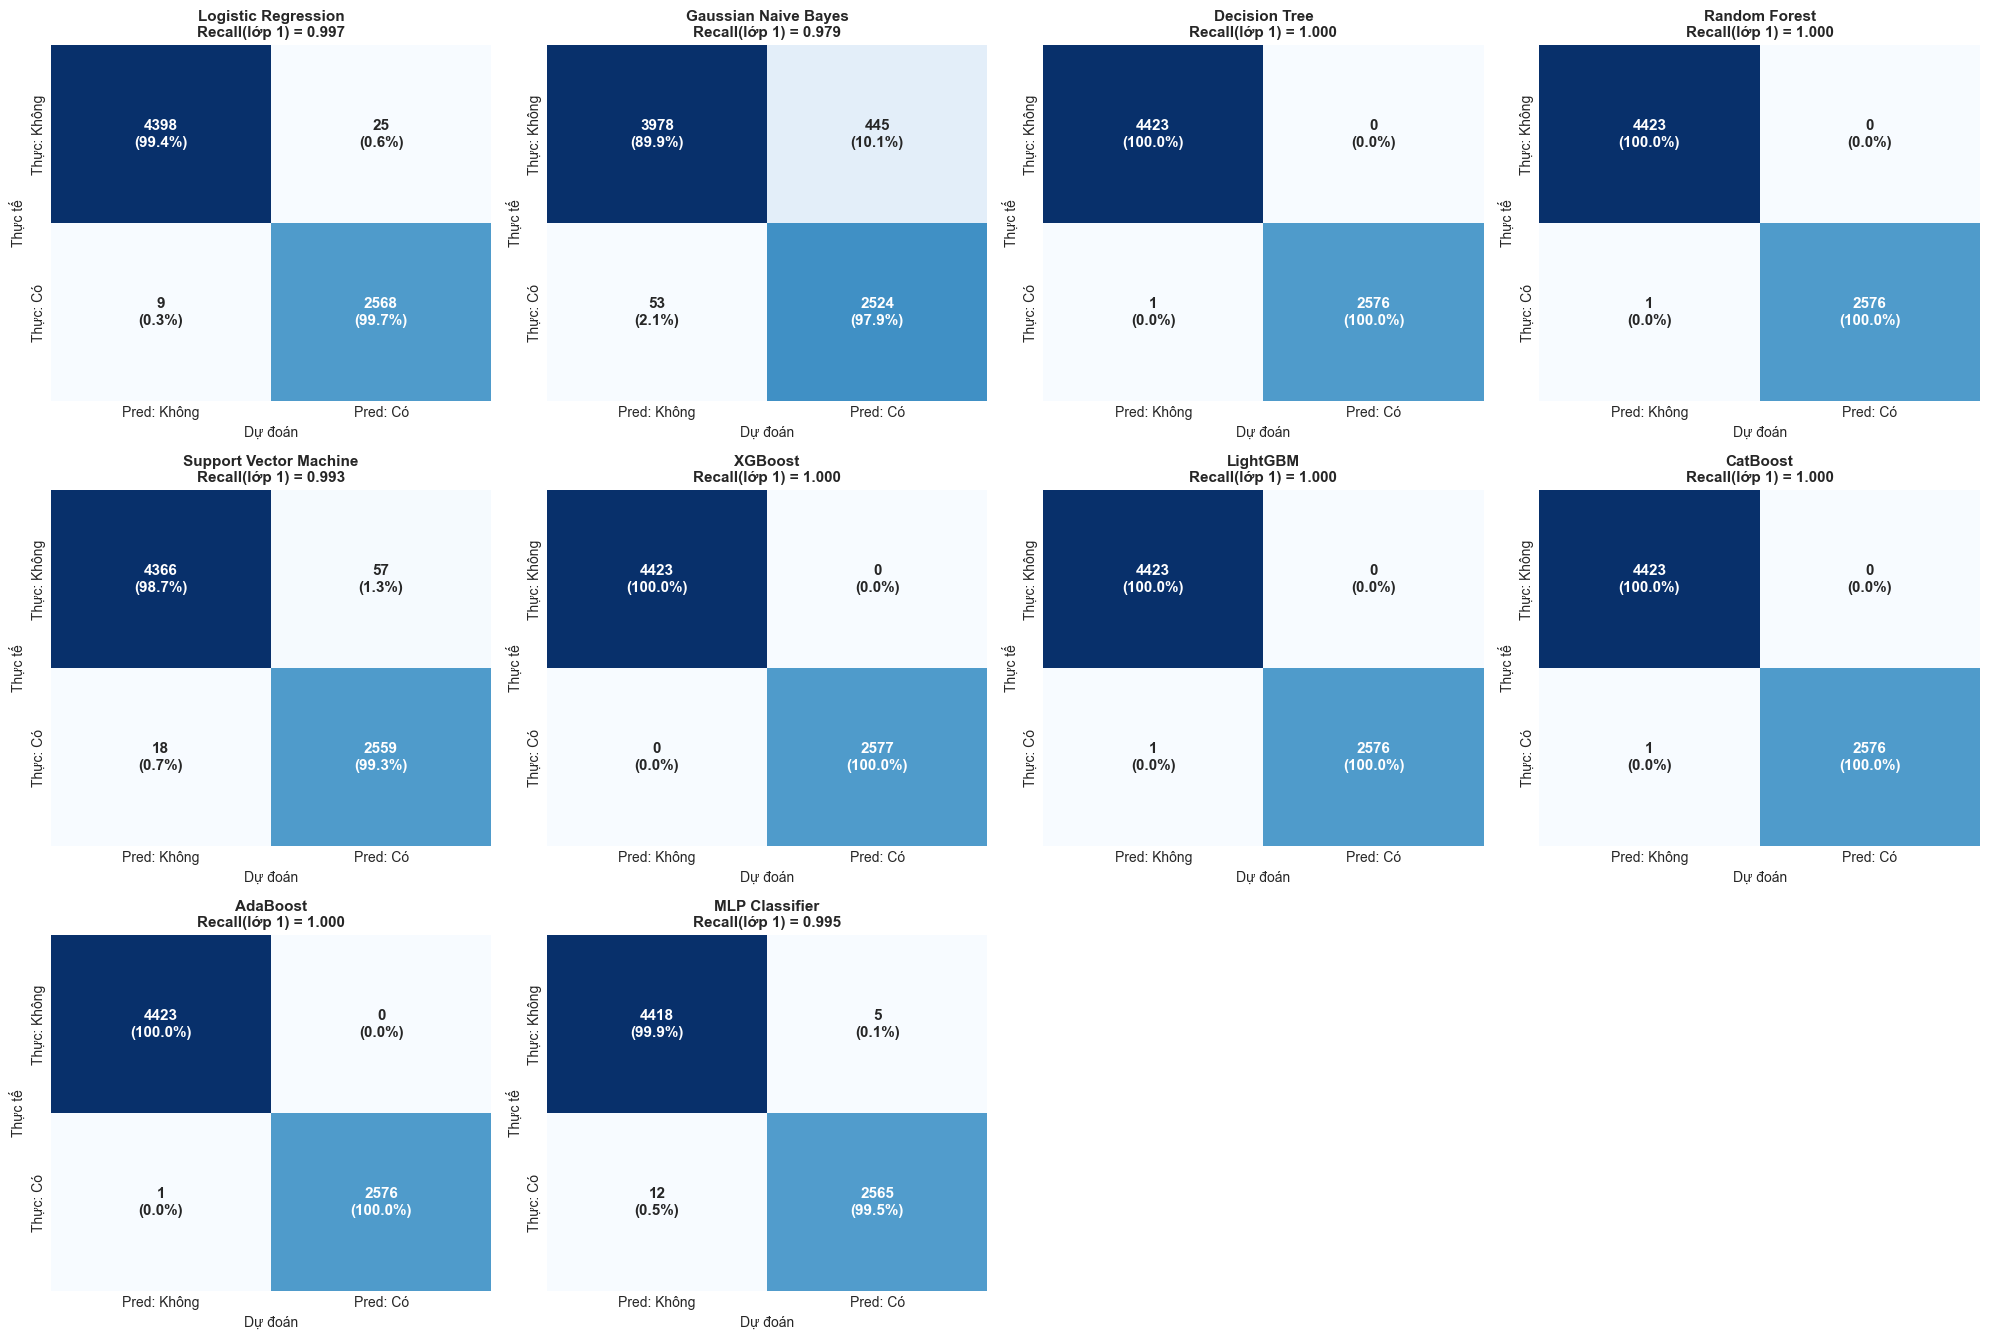


8.2. BẢNG CHỈ SỐ CHI TIẾT TRÊN TẬP TEST


,Model,Accuracy,Precision (lớp 1),Recall (lớp 1),Specificity (lớp 0),F1 (lớp 1),TN,FP,FN,TP
0,XGBoost,1.0000,1.0000,1.0000,1.0000,1.0000,4423,0,0,2577
1,Decision Tree,0.9999,1.0000,0.9996,1.0000,0.9998,4423,0,1,2576
2,Random Forest,0.9999,1.0000,0.9996,1.0000,0.9998,4423,0,1,2576
3,LightGBM,0.9999,1.0000,0.9996,1.0000,0.9998,4423,0,1,2576
4,CatBoost,0.9999,1.0000,0.9996,1.0000,0.9998,4423,0,1,2576
5,AdaBoost,0.9999,1.0000,0.9996,1.0000,0.9998,4423,0,1,2576
6,MLP Classifier,0.9976,0.9981,0.9953,0.9989,0.9967,4418,5,12,2565
7,Logistic Regression,0.9951,0.9904,0.9965,0.9943,0.9934,4398,25,9,2568
8,Support Vector Machine,0.9893,0.9782,0.9930,0.9871,0.9856,4366,57,18,2559
9,Gaussian Naive Bayes,0.9289,0.8501,0.9794,0.8994,0.9102,3978,445,53,2524



✅ Đã lưu bảng đánh giá vào 'models/evaluation_summary.csv'

8.3. CLASSIFICATION REPORT CHO MODEL TỐT NHẤT
🏆 Model tốt nhất theo F1: XGBoost

                   precision    recall  f1-score   support

Không nguy cơ (0)     1.0000    1.0000    1.0000      4423
   Có nguy cơ (1)     1.0000    1.0000    1.0000      2577

         accuracy                         1.0000      7000
        macro avg     1.0000    1.0000    1.0000      7000
     weighted avg     1.0000    1.0000    1.0000      7000



In [8]:
# ==============================================================================
# PHẦN 8: CONFUSION MATRIX & EVALUATION VISUALIZATION (AUTO-DETECT TARGET V2)
# Vị trí: Cell trong notebooks/Stroke_Prediction.ipynb
# ==============================================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

# ==============================================================================
# 8.0. TỰ ĐỘNG XÁC ĐỊNH TARGET VÀ PIPELINE
# ==============================================================================
target_df_check = df_clean if "df_clean" in globals() else df

if "at_risk" in target_df_check.columns:
    TARGET_COL = "at_risk"
elif "stroke" in target_df_check.columns:
    TARGET_COL = "stroke"
else:
    TARGET_COL = target_df_check.columns[-1]

# Nhãn hiển thị song ngữ
CLASS_LABELS = ["Không nguy cơ (0)", "Có nguy cơ (1)"]

print("==========================================")
print(f"8.0. CẤU HÌNH ĐÁNH GIÁ - TARGET: '{TARGET_COL}'")
print("==========================================")

# Chọn pipeline ưu tiên: Tuned > SMOTE > Baseline
if "tuned_best_pipelines" in globals() and len(tuned_best_pipelines) > 0:
    pipelines_to_plot = tuned_best_pipelines
    print("📌 Đang dùng: tuned_best_pipelines (Phần 10)")
elif "fitted_smote_pipelines" in globals() and len(fitted_smote_pipelines) > 0:
    pipelines_to_plot = fitted_smote_pipelines
    print("📌 Đang dùng: fitted_smote_pipelines (Phần 7)")
else:
    pipelines_to_plot = fitted_baseline_pipelines
    print("📌 Đang dùng: fitted_baseline_pipelines (Phần 6)")

# ==============================================================================
# 8.1. CONFUSION MATRIX CHO CÁC MODELS
# ==============================================================================
print("\n==========================================")
print("8.1. CONFUSION MATRIX CHO CÁC MODELS")
print("==========================================")

n_models = len(pipelines_to_plot)

if n_models == 0:
    print("❌ Chưa có mô hình nào được huấn luyện thành công để vẽ Confusion Matrix.")
else:
    # Tính số hàng, số cột an toàn (luôn >= 1)
    ncols = min(4, n_models)
    nrows = (n_models + ncols - 1) // ncols

    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.5 * nrows))

    # Chuẩn hóa axes thành mảng 1D để dễ index
    if n_models == 1:
        axes = np.array([axes])
    else:
        axes = np.array(axes).flatten()

    # Tính toán trước để đồng nhất
    for idx, (name, pipeline) in enumerate(pipelines_to_plot.items()):
        y_pred = pipeline.predict(X_test)

        # Đảm bảo labels luôn là [0, 1] để ma trận 2x2 nhất quán
        cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

        # Tạo annotation hiển thị cả số lượng và phần trăm theo hàng
        cm_sum = cm.sum(axis=1, keepdims=True)
        cm_pct = np.divide(
            cm, cm_sum, out=np.zeros_like(cm, dtype=float), where=cm_sum != 0
        )

        annot = np.array(
            [
                [
                    f"{cm[i, j]}\n({cm_pct[i, j] * 100:.1f}%)"
                    for j in range(cm.shape[1])
                ]
                for i in range(cm.shape[0])
            ]
        )

        sns.heatmap(
            cm,
            annot=annot,
            fmt="",
            cmap="Blues",
            ax=axes[idx],
            cbar=False,
            xticklabels=["Pred: Không", "Pred: Có"],
            yticklabels=["Thực: Không", "Thực: Có"],
            annot_kws={"size": 11, "weight": "bold"},
        )

        # Thêm Recall của lớp 1 vào tiêu đề
        rec_1 = cm[1, 1] / max(cm[1, 0] + cm[1, 1], 1)
        axes[idx].set_title(
            f"{name}\nRecall(lớp 1) = {rec_1:.3f}",
            fontsize=11,
            fontweight="bold",
        )
        axes[idx].set_xlabel("Dự đoán")
        axes[idx].set_ylabel("Thực tế")

    # Ẩn các subplot thừa
    for j in range(n_models, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

    # ==============================================================================
    # 8.2. BẢNG CHỈ SỐ CHI TIẾT TỪNG MODEL (ĐÁNH GIÁ TRÊN TEST)
    # ==============================================================================
    print("\n==========================================")
    print("8.2. BẢNG CHỈ SỐ CHI TIẾT TRÊN TẬP TEST")
    print("==========================================")

    summary_rows = []
    for name, pipeline in pipelines_to_plot.items():
        y_pred = pipeline.predict(X_test)

        # Lấy confusion matrix để tính Specificity
        cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
        tn, fp, fn, tp = cm.ravel()
        specificity = tn / max(tn + fp, 1)

        summary_rows.append({
            "Model": name,
            "Accuracy": round((tp + tn) / max(cm.sum(), 1), 4),
            "Precision (lớp 1)": round(precision_score(y_test, y_pred, zero_division=0), 4),
            "Recall (lớp 1)": round(recall_score(y_test, y_pred, zero_division=0), 4),
            "Specificity (lớp 0)": round(specificity, 4),
            "F1 (lớp 1)": round(f1_score(y_test, y_pred, zero_division=0), 4),
            "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        })

    df_eval = (
        pd.DataFrame(summary_rows)
        .sort_values(by="F1 (lớp 1)", ascending=False)
        .reset_index(drop=True)
    )
    display(df_eval)

    # Lưu bảng đánh giá ra CSV
    import os
    os.makedirs("models", exist_ok=True)
    df_eval.to_csv("models/evaluation_summary.csv", index=False)
    print("\n✅ Đã lưu bảng đánh giá vào 'models/evaluation_summary.csv'")


# ==============================================================================
# 8.3. (TÙY CHỌN) CLASSIFICATION REPORT CHI TIẾT CHO MODEL TỐT NHẤT
# ==============================================================================
print("\n==========================================")
print("8.3. CLASSIFICATION REPORT CHO MODEL TỐT NHẤT")
print("==========================================")

if n_models > 0:
    # Chọn model có F1 cao nhất từ bảng df_eval
    best_eval_name = df_eval.iloc[0]["Model"]
    best_eval_pipe = pipelines_to_plot[best_eval_name]
    y_pred_best = best_eval_pipe.predict(X_test)

    print(f"🏆 Model tốt nhất theo F1: {best_eval_name}\n")
    print(classification_report(
        y_test,
        y_pred_best,
        target_names=CLASS_LABELS,
        digits=4,
        zero_division=0,
    ))

In [9]:
# ==============================================================================
# PHẦN 9: STRATIFIED K-FOLD CROSS-VALIDATION (AUTO-DETECT SMOTE RATIO)
# ==============================================================================

import numpy as np
import pandas as pd
from collections import Counter
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

print("==========================================")
print("9.1. THỰC HIỆN 5-FOLD STRATIFIED CROSS VALIDATION (ON TRAIN SET ONLY)")
print("==========================================")

# --- Tự động xác định chiến lược SMOTE an toàn ---
class_counts = Counter(y_train)
n_neg, n_pos = class_counts.get(0, 1), class_counts.get(1, 1)
current_ratio = n_pos / max(n_neg, 1)
TARGET_SMOTE_RATIO = 0.5

if current_ratio >= TARGET_SMOTE_RATIO:
    SMOTE_STRATEGY = "auto" if current_ratio < 1.0 else None
    USE_SMOTE = SMOTE_STRATEGY is not None
    print(f"⚠️ Tỷ lệ hiện tại = {current_ratio:.4f} ≥ {TARGET_SMOTE_RATIO} → dùng strategy = {SMOTE_STRATEGY}")
else:
    SMOTE_STRATEGY = TARGET_SMOTE_RATIO
    USE_SMOTE = True
    print(f"✅ Tỷ lệ hiện tại = {current_ratio:.4f} < {TARGET_SMOTE_RATIO} → dùng strategy = {SMOTE_STRATEGY}")

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring_metrics = ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"]

cv_results_list = []
models_for_cv = raw_models if "raw_models" in globals() else {}

print("\n⏳ Đang chạy Cross-Validation...")

for name, model in models_for_cv.items():
    try:
        # Cấu hình bước SMOTE tùy theo phân phối lớp
        if USE_SMOTE:
            steps = [
                ("preprocessor", preprocessor),
                ("smote", SMOTE(sampling_strategy=SMOTE_STRATEGY,
                                random_state=42,
                                k_neighbors=min(5, n_pos - 1) if n_pos > 1 else 1)),
                ("classifier", model),
            ]
        else:
            steps = [
                ("preprocessor", preprocessor),
                ("classifier", model),
            ]

        cv_pipeline = ImbPipeline(steps=steps)

        cv_scores = cross_validate(
            estimator=cv_pipeline,
            X=X_train, y=y_train,
            cv=skf, scoring=scoring_metrics,
            n_jobs=1, error_score="raise",
        )

        cv_results_list.append({
            "Model": name,
            "CV Accuracy Mean": round(np.mean(cv_scores["test_accuracy"]), 4),
            "CV Precision Mean": round(np.mean(cv_scores["test_precision"]), 4),
            "CV Recall Mean": round(np.mean(cv_scores["test_recall"]), 4),
            "CV F1 Mean": round(np.mean(cv_scores["test_f1"]), 4),
            "CV ROC-AUC Mean": round(np.mean(cv_scores["test_roc_auc"]), 4),
            "CV PR-AUC Mean": round(np.mean(cv_scores["test_average_precision"]), 4),
            "CV F1 Std": round(np.std(cv_scores["test_f1"]), 4),
            "CV PR-AUC Std": round(np.std(cv_scores["test_average_precision"]), 4),
        })
        print(f"✔️ CV hoàn thành: {name}")
    except Exception as e:
        print(f"⚠️ Bỏ qua '{name}': {type(e).__name__}: {e}")

print("\n==========================================")
print("9.2. BẢNG KẾT QUẢ CROSS-VALIDATION (SORTED BY PR-AUC)")
print("==========================================")

if cv_results_list:
    df_cv_results = pd.DataFrame(cv_results_list).sort_values(
        by=["CV PR-AUC Mean", "CV Recall Mean"], ascending=False
    ).reset_index(drop=True)
    display(df_cv_results)
else:
    print("❌ Chưa thực hiện CV thành công cho mô hình nào.")

9.1. THỰC HIỆN 5-FOLD STRATIFIED CROSS VALIDATION (ON TRAIN SET ONLY)
⚠️ Tỷ lệ hiện tại = 0.5828 ≥ 0.5 → dùng strategy = auto

⏳ Đang chạy Cross-Validation...
✔️ CV hoàn thành: Logistic Regression
✔️ CV hoàn thành: Gaussian Naive Bayes
✔️ CV hoàn thành: K-Nearest Neighbors
✔️ CV hoàn thành: Decision Tree
✔️ CV hoàn thành: Random Forest
✔️ CV hoàn thành: Support Vector Machine
✔️ CV hoàn thành: XGBoost
✔️ CV hoàn thành: LightGBM
✔️ CV hoàn thành: CatBoost
✔️ CV hoàn thành: AdaBoost
✔️ CV hoàn thành: MLP Classifier

9.2. BẢNG KẾT QUẢ CROSS-VALIDATION (SORTED BY PR-AUC)


,Model,CV Accuracy Mean,CV Precision Mean,CV Recall Mean,CV F1 Mean,CV ROC-AUC Mean,CV PR-AUC Mean,CV F1 Std,CV PR-AUC Std
0,Decision Tree,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,0.0000
1,Random Forest,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,0.0000
2,XGBoost,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,0.0000
3,LightGBM,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,0.0000
4,CatBoost,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,0.0000
5,AdaBoost,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,0.0000
6,MLP Classifier,0.9977,0.9974,0.9964,0.9969,1.0000,1.0000,0.0008,0.0000
7,Logistic Regression,0.9934,0.9880,0.9942,0.9911,0.9999,0.9998,0.0016,0.0001
8,Support Vector Machine,0.9892,0.9787,0.9923,0.9855,0.9997,0.9994,0.0016,0.0001
9,Gaussian Naive Bayes,0.9318,0.8549,0.9812,0.9137,0.9907,0.9847,0.0031,0.0017


In [10]:
# ==============================================================================
# PHẦN 10: HYPERPARAMETER TUNING VỚI RANDOMIZEDSEARCHCV (AUTO-DETECT SMOTE)
# ==============================================================================

import numpy as np
import pandas as pd
from collections import Counter
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score, roc_auc_score
from sklearn.model_selection import ParameterGrid, RandomizedSearchCV, StratifiedKFold
from xgboost import XGBClassifier

print("==========================================")
print("10.1. THIẾT LẬP LƯỚI THAM SỐ (PARAM GRIDS)")
print("==========================================")

param_grids = {
    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1.0, 10.0],
        "classifier__solver": ["liblinear", "lbfgs"],
    },
    "Random Forest": {
        "classifier__n_estimators": [100, 200, 300],
        "classifier__max_depth": [None, 10, 20],
        "classifier__min_samples_split": [2, 5, 10],
    },
    "XGBoost": {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [3, 6, 10],
        "classifier__learning_rate": [0.01, 0.1, 0.2],
    },
}

tune_candidate_models = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000),
    "Random Forest": RandomForestClassifier(random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(random_state=42, eval_metric="logloss", verbosity=0),
}

# --- Tự động xác định chiến lược SMOTE ---
class_counts = Counter(y_train)
n_neg, n_pos = class_counts.get(0, 1), class_counts.get(1, 1)
current_ratio = n_pos / max(n_neg, 1)

if current_ratio >= 0.5:
    SMOTE_STRATEGY = "auto" if current_ratio < 1.0 else None
    USE_SMOTE = SMOTE_STRATEGY is not None
else:
    SMOTE_STRATEGY = 0.5
    USE_SMOTE = True

print(f"\n📊 SMOTE strategy cho tuning = {SMOTE_STRATEGY} (USE_SMOTE = {USE_SMOTE})")

print("\n==========================================")
print("10.2. TUNING BẰNG RANDOMIZEDSEARCHCV (SCORING = PR-AUC)")
print("==========================================")

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
tuned_best_pipelines = {}
tuning_summary = []

for name, model in tune_candidate_models.items():
    if name not in param_grids:
        continue

    print(f"⏳ Đang tuning: {name}...")

    if USE_SMOTE:
        steps = [
            ("preprocessor", preprocessor),
            ("smote", SMOTE(sampling_strategy=SMOTE_STRATEGY, random_state=42,
                            k_neighbors=min(5, n_pos - 1) if n_pos > 1 else 1)),
            ("classifier", model),
        ]
    else:
        steps = [
            ("preprocessor", preprocessor),
            ("classifier", model),
        ]
    pipeline = ImbPipeline(steps=steps)

    n_iter = min(10, len(ParameterGrid(param_grids[name])))

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_grids[name],
        n_iter=n_iter,
        scoring="average_precision",
        cv=skf, random_state=42, n_jobs=1, error_score="raise",
    )

    try:
        search.fit(X_train, y_train)
        best_pipe = search.best_estimator_

        y_pred = best_pipe.predict(X_test)
        y_proba = (best_pipe.predict_proba(X_test)[:, 1]
                   if hasattr(best_pipe, "predict_proba")
                   else best_pipe.decision_function(X_test))

        tuned_best_pipelines[name] = best_pipe
        tuning_summary.append({
            "Model": name,
            "Best CV PR-AUC": round(search.best_score_, 4),
            "Test PR-AUC": round(average_precision_score(y_test, y_proba), 4),
            "Test F1": round(f1_score(y_test, y_pred, zero_division=0), 4),
            "Test ROC-AUC": round(roc_auc_score(y_test, y_proba), 4),
            "Best Params": search.best_params_,
        })
        print(f"✔️ {name} | CV PR-AUC = {round(search.best_score_, 4)} | Test PR-AUC = {round(average_precision_score(y_test, y_proba), 4)}")
    except Exception as e:
        print(f"⚠️ Bỏ qua tuning '{name}': {type(e).__name__}: {e}")

# ------------------------------------------------------------------------------
# 10.3. BẢNG TỔNG HỢP
# ------------------------------------------------------------------------------
print("\n==========================================")
print("10.3. KẾT QUẢ SAU TUNING (SORTED BY CV PR-AUC)")
print("==========================================")

if tuning_summary:
    df_tuning = pd.DataFrame(tuning_summary).sort_values(
        by="Best CV PR-AUC", ascending=False
    ).reset_index(drop=True)
    display(df_tuning)

    best_model_name = df_tuning.iloc[0]["Model"]
    final_pipeline = tuned_best_pipelines[best_model_name]
    print(f"\n🏆 Mô hình chọn theo CV PR-AUC: {best_model_name}")
    print("ℹ️ Model cuối cùng sẽ được lưu ở PHẦN 11.5.")
else:
    print("❌ Chưa tuning thành công mô hình nào.")

10.1. THIẾT LẬP LƯỚI THAM SỐ (PARAM GRIDS)

📊 SMOTE strategy cho tuning = auto (USE_SMOTE = True)

10.2. TUNING BẰNG RANDOMIZEDSEARCHCV (SCORING = PR-AUC)
⏳ Đang tuning: Logistic Regression...
✔️ Logistic Regression | CV PR-AUC = 0.9999 | Test PR-AUC = 1.0
⏳ Đang tuning: Random Forest...
✔️ Random Forest | CV PR-AUC = 1.0 | Test PR-AUC = 1.0
⏳ Đang tuning: XGBoost...
✔️ XGBoost | CV PR-AUC = 1.0 | Test PR-AUC = 1.0

10.3. KẾT QUẢ SAU TUNING (SORTED BY CV PR-AUC)


,Model,Best CV PR-AUC,Test PR-AUC,Test F1,Test ROC-AUC,Best Params
0,Random Forest,1.0000,1.0,0.9998,1.0,"{'classifier__n_estimators': 300, 'classifier_..."
1,XGBoost,1.0000,1.0,1.0000,1.0,"{'classifier__n_estimators': 100, 'classifier_..."
2,Logistic Regression,0.9999,1.0,0.9965,1.0,"{'classifier__solver': 'lbfgs', 'classifier__C..."



🏆 Mô hình chọn theo CV PR-AUC: Random Forest
ℹ️ Model cuối cùng sẽ được lưu ở PHẦN 11.5.


11.1. ĐÁNH GIÁ MÔ HÌNH SAU TUNING TRÊN TẬP TEST

--- BẢNG SO SÁNH TRƯỚC/SAU TUNING (ngưỡng 0.5) ---


,Model,Baseline PR-AUC,Tuned PR-AUC,Baseline Recall,Tuned Recall,Baseline F1,Tuned F1,Baseline ROC-AUC,Tuned ROC-AUC,Tuned Accuracy,Tuned Precision
0,Logistic Regression,0.9998,1.0,0.9965,0.9969,0.9934,0.9965,0.9999,1.0,0.9974,0.9961
1,Random Forest,1.0000,1.0,0.9996,0.9996,0.9998,0.9998,1.0000,1.0,0.9999,1.0000
2,XGBoost,1.0000,1.0,1.0000,1.0000,1.0000,1.0000,1.0000,1.0,1.0000,1.0000



11.2. LỰA CHỌN MÔ HÌNH CUỐI CÙNG (THEO CV PR-AUC)
🏆 MÔ HÌNH CUỐI CÙNG: RANDOM FOREST
  Accuracy : 0.9999
  Precision: 1.0000
  Recall   : 0.9996
  F1-Score : 0.9998
  ROC-AUC  : 1.0000
  PR-AUC   : 1.0000

11.3. FEATURE IMPORTANCE CỦA FINAL MODEL


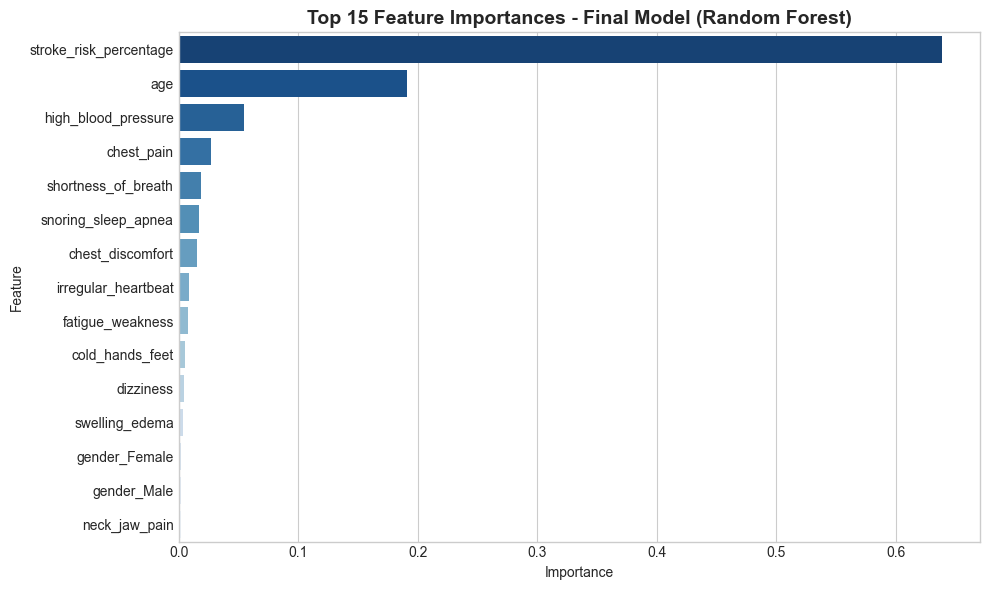

,Feature,Importance
0,stroke_risk_percentage,0.638757
1,age,0.190851
2,high_blood_pressure,0.054712
3,chest_pain,0.027046
4,shortness_of_breath,0.018534
5,snoring_sleep_apnea,0.016830
6,chest_discomfort,0.015641
7,irregular_heartbeat,0.008742
8,fatigue_weakness,0.008111
9,cold_hands_feet,0.005084



11.4. CALIBRATION VÀ CHỌN NGƯỠNG QUYẾT ĐỊNH
Ngưỡng quyết định (recall mục tiêu 80%): 0.9994

--- KẾT QUẢ CUỐI CÙNG (calibrate + ngưỡng mới) ---
               precision    recall  f1-score   support

Không nguy cơ       0.96      1.00      0.98      4423
   Có nguy cơ       1.00      0.93      0.96      2577

     accuracy                           0.97      7000
    macro avg       0.98      0.96      0.97      7000
 weighted avg       0.97      0.97      0.97      7000

Confusion matrix:
 [[4423    0]
 [ 192 2385]]
PR-AUC : 1.0000
ROC-AUC: 1.0000
Brier  : trước = 0.0002 | sau = 0.0001


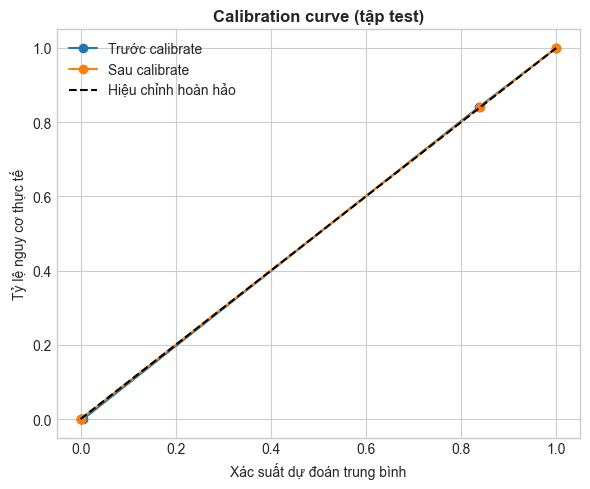


11.5. LƯU MODEL + NGƯỠNG VÀ TEST VỚI BỆNH NHÂN MẪU
✅ Đã lưu 'stroke_model.pkl' và 'threshold.json'!
✅ Đã load lại model và ngưỡng từ đĩa!

Bệnh nhân test có 18 cột.
{'age': 46, 'gender': 'Female', 'chest_pain': 0, 'high_blood_pressure': 0, 'irregular_heartbeat': 0, 'shortness_of_breath': 1, 'fatigue_weakness': 0, 'dizziness': 0, 'swelling_edema': 0, 'neck_jaw_pain': 0, 'excessive_sweating': 0, 'persistent_cough': 0, 'nausea_vomiting': 0, 'chest_discomfort': 0, 'cold_hands_feet': 1, 'snoring_sleep_apnea': 1, 'anxiety_doom': 0, 'stroke_risk_percentage': 59.8}

--- KẾT QUẢ DỰ ĐOÁN CHO BỆNH NHÂN MẪU ---
Nhãn thực tế       : 1
Xác suất nguy cơ   : 99.95%
Ngưỡng quyết định  : 99.94%
Kết luận           : ⚠️ CÓ NGUY CƠ CAO


In [11]:
# ==============================================================================
# PHẦN 11: SO SÁNH TRƯỚC/SAU TUNING, FEATURE IMPORTANCE, CALIBRATION & LƯU MODEL
# ==============================================================================

import json, os
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss,
                              classification_report, confusion_matrix, f1_score,
                              precision_recall_curve, precision_score, recall_score,
                              roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_val_predict

try:
    from sklearn.inspection import permutation_importance
except ImportError:
    permutation_importance = None

# ------------------------------------------------------------------------------
# 11.1. BẢNG SO SÁNH TRƯỚC/SAU TUNING
# ------------------------------------------------------------------------------
print("==========================================")
print("11.1. ĐÁNH GIÁ MÔ HÌNH SAU TUNING TRÊN TẬP TEST")
print("==========================================")

if "tuned_best_pipelines" not in globals() or len(tuned_best_pipelines) == 0:
    print("⚠️ Chưa có 'tuned_best_pipelines', fallback...")
    pipelines_to_use = (
        fitted_smote_pipelines
        if ("fitted_smote_pipelines" in globals() and len(fitted_smote_pipelines) > 0)
        else fitted_baseline_pipelines
    )
else:
    pipelines_to_use = tuned_best_pipelines

comparison_before_after = []
for name, pipe in pipelines_to_use.items():
    y_pred = pipe.predict(X_test)
    y_proba = (pipe.predict_proba(X_test)[:, 1]
               if hasattr(pipe, "predict_proba")
               else pipe.decision_function(X_test))

    base_f1 = base_rec = base_auc = base_pr = np.nan
    if "df_smote" in globals() and name in df_smote["Model"].values:
        row = df_smote[df_smote["Model"] == name].iloc[0]
        base_f1, base_rec = row.get("F1", np.nan), row.get("Recall", np.nan)
        base_auc, base_pr = row.get("ROC-AUC", np.nan), row.get("PR-AUC", np.nan)

    comparison_before_after.append({
        "Model": name,
        "Baseline PR-AUC": base_pr,
        "Tuned PR-AUC": round(average_precision_score(y_test, y_proba), 4),
        "Baseline Recall": base_rec,
        "Tuned Recall": round(recall_score(y_test, y_pred, zero_division=0), 4),
        "Baseline F1": base_f1,
        "Tuned F1": round(f1_score(y_test, y_pred, zero_division=0), 4),
        "Baseline ROC-AUC": base_auc,
        "Tuned ROC-AUC": round(roc_auc_score(y_test, y_proba), 4),
        "Tuned Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Tuned Precision": round(precision_score(y_test, y_pred, zero_division=0), 4),
    })

df_comparison = (pd.DataFrame(comparison_before_after)
                 .sort_values(by="Tuned PR-AUC", ascending=False)
                 .reset_index(drop=True))
print("\n--- BẢNG SO SÁNH TRƯỚC/SAU TUNING (ngưỡng 0.5) ---")
display(df_comparison)


# ------------------------------------------------------------------------------
# 11.2. CHỌN MÔ HÌNH CUỐI CÙNG
# ------------------------------------------------------------------------------
print("\n==========================================")
print("11.2. LỰA CHỌN MÔ HÌNH CUỐI CÙNG (THEO CV PR-AUC)")
print("==========================================")

best_model_name = None
if "df_tuning" in globals() and len(df_tuning) > 0:
    best_model_name = df_tuning.iloc[0]["Model"]
elif "df_cv_results" in globals():
    for m in df_cv_results["Model"]:
        if m in pipelines_to_use:
            best_model_name = m
            break
if best_model_name is None:
    best_model_name = list(pipelines_to_use.keys())[0]
    print("⚠️ Không có bảng CV, dùng mô hình đầu tiên.")

final_pipeline = pipelines_to_use[best_model_name]
print(f"🏆 MÔ HÌNH CUỐI CÙNG: {best_model_name.upper()}")

y_pred_final = final_pipeline.predict(X_test)
y_proba_final = final_pipeline.predict_proba(X_test)[:, 1]
print(f"  Accuracy : {accuracy_score(y_test, y_pred_final):.4f}")
print(f"  Precision: {precision_score(y_test, y_pred_final, zero_division=0):.4f}")
print(f"  Recall   : {recall_score(y_test, y_pred_final, zero_division=0):.4f}")
print(f"  F1-Score : {f1_score(y_test, y_pred_final, zero_division=0):.4f}")
print(f"  ROC-AUC  : {roc_auc_score(y_test, y_proba_final):.4f}")
print(f"  PR-AUC   : {average_precision_score(y_test, y_proba_final):.4f}")


# ------------------------------------------------------------------------------
# 11.3. FEATURE IMPORTANCE
# ------------------------------------------------------------------------------
print("\n==========================================")
print("11.3. FEATURE IMPORTANCE CỦA FINAL MODEL")
print("==========================================")

try:
    raw_names = final_pipeline.named_steps["preprocessor"].get_feature_names_out()
    all_feature_names = [n.split("__", 1)[1] for n in raw_names]
except Exception:
    all_feature_names = None

clf = final_pipeline.named_steps["classifier"]

if hasattr(clf, "feature_importances_"):
    importances = clf.feature_importances_
elif hasattr(clf, "coef_"):
    importances = np.abs(clf.coef_[0])
elif permutation_importance is not None:
    print("Tính Permutation Importance...")
    perm = permutation_importance(final_pipeline, X_test, y_test,
                                   scoring="average_precision", n_repeats=5, random_state=42)
    importances = perm.importances_mean
    all_feature_names = list(X_test.columns)
else:
    importances = np.zeros(len(X_test.columns))
    all_feature_names = list(X_test.columns)

if all_feature_names is None or len(all_feature_names) != len(importances):
    all_feature_names = [f"feature_{i}" for i in range(len(importances))]

feat_imp_df = (pd.DataFrame({"Feature": all_feature_names, "Importance": importances})
               .sort_values(by="Importance", ascending=False).reset_index(drop=True))

plt.figure(figsize=(10, 6))
sns.barplot(x="Importance", y="Feature", data=feat_imp_df.head(15),
            palette="Blues_r", hue="Feature", legend=False)
plt.title(f"Top 15 Feature Importances - Final Model ({best_model_name})",
          fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()
display(feat_imp_df)


# ------------------------------------------------------------------------------
# 11.4. CALIBRATION + CHỌN NGƯỠNG
# ------------------------------------------------------------------------------
print("\n==========================================")
print("11.4. CALIBRATION VÀ CHỌN NGƯỠNG QUYẾT ĐỊNH")
print("==========================================")

TARGET_RECALL = 0.80
skf_cal = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

calibrated_model = CalibratedClassifierCV(final_pipeline, method="sigmoid", cv=5)
calibrated_model.fit(X_train, y_train)

oof_proba = cross_val_predict(
    CalibratedClassifierCV(final_pipeline, method="sigmoid", cv=5),
    X_train, y_train, cv=skf_cal, method="predict_proba", n_jobs=1,
)[:, 1]

prec_c, rec_c, thr_c = precision_recall_curve(y_train, oof_proba)
ok = np.where(rec_c[:-1] >= TARGET_RECALL)[0]
if len(ok) > 0:
    decision_threshold = float(thr_c[ok[-1]])
else:
    decision_threshold = 0.5
    print("⚠️ Không đạt recall mục tiêu, dùng ngưỡng 0.5")
print(f"Ngưỡng quyết định (recall mục tiêu {TARGET_RECALL:.0%}): {decision_threshold:.4f}")

p_cal = calibrated_model.predict_proba(X_test)[:, 1]
y_pred_cal = (p_cal >= decision_threshold).astype(int)

print("\n--- KẾT QUẢ CUỐI CÙNG (calibrate + ngưỡng mới) ---")
print(classification_report(y_test, y_pred_cal,
                             target_names=["Không nguy cơ", "Có nguy cơ"], zero_division=0))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred_cal))
print(f"PR-AUC : {average_precision_score(y_test, p_cal):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, p_cal):.4f}")
print(f"Brier  : trước = {brier_score_loss(y_test, y_proba_final):.4f} | sau = {brier_score_loss(y_test, p_cal):.4f}")

plt.figure(figsize=(6, 5))
for label, p in [("Trước calibrate", y_proba_final), ("Sau calibrate", p_cal)]:
    frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=5, strategy="quantile")
    plt.plot(mean_pred, frac_pos, marker="o", label=label)
plt.plot([0, 1], [0, 1], "k--", label="Hiệu chỉnh hoàn hảo")
plt.xlabel("Xác suất dự đoán trung bình")
plt.ylabel("Tỷ lệ nguy cơ thực tế")
plt.title("Calibration curve (tập test)", fontweight="bold")
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------------------------
# 11.5. LƯU MODEL + NGƯỠNG, RE-LOAD VÀ TEST VỚI BỆNH NHÂN ĐỘNG
# ------------------------------------------------------------------------------
print("\n==========================================")
print("11.5. LƯU MODEL + NGƯỠNG VÀ TEST VỚI BỆNH NHÂN MẪU")
print("==========================================")

for folder in ["models", "../models"]:
    os.makedirs(folder, exist_ok=True)
    joblib.dump(calibrated_model, f"{folder}/stroke_model.pkl")
    with open(f"{folder}/threshold.json", "w", encoding="utf-8") as f:
        json.dump(
            {
                "threshold": decision_threshold,
                "target_recall": TARGET_RECALL,
                "model": best_model_name,
                "target_column": TARGET_COL,
            },
            f, ensure_ascii=False, indent=2,
        )
print("✅ Đã lưu 'stroke_model.pkl' và 'threshold.json'!")

loaded_model = joblib.load("models/stroke_model.pkl")
with open("models/threshold.json", encoding="utf-8") as f:
    loaded_threshold = json.load(f)["threshold"]
print("✅ Đã load lại model và ngưỡng từ đĩa!")

# --- TỰ ĐỘNG SINH BỆNH NHÂN MẪU TỪ CHÍNH DỮ LIỆU X_test ---
# Lấy 1 dòng bệnh nhân nguy cơ cao (nhãn 1) nếu có, không thì lấy dòng đầu
sample_df = X_test.copy()
if TARGET_COL in sample_df.columns:
    sample_df = sample_df.drop(columns=[TARGET_COL], errors="ignore")

pos_idx = y_test[y_test == 1].index
if len(pos_idx) > 0:
    sample_patient = sample_df.loc[[pos_idx[0]]].copy()
    actual_label = 1
else:
    sample_patient = sample_df.head(1).copy()
    actual_label = int(y_test.iloc[0])

# Đảm bảo đủ cột mà model cần
print(f"\nBệnh nhân test có {sample_patient.shape[1]} cột.")
print(sample_patient.to_dict(orient="records")[0])

sample_proba = loaded_model.predict_proba(sample_patient)[0][1]
sample_pred = int(sample_proba >= loaded_threshold)

print("\n--- KẾT QUẢ DỰ ĐOÁN CHO BỆNH NHÂN MẪU ---")
print(f"Nhãn thực tế       : {actual_label}")
print(f"Xác suất nguy cơ   : {sample_proba * 100:.2f}%")
print(f"Ngưỡng quyết định  : {loaded_threshold * 100:.2f}%")
print(f"Kết luận           : {'⚠️ CÓ NGUY CƠ CAO' if sample_pred == 1 else '✅ Nguy cơ thấp'}")

In [12]:
import os
import joblib

# Tạo các thư mục nếu chưa có
os.makedirs("models", exist_ok=True)
os.makedirs("../models", exist_ok=True)

# Lưu pipeline mô hình đã train (biến final_pipeline hoặc best_pipeline)
joblib.dump(final_pipeline, "models/stroke_model.pkl")
joblib.dump(final_pipeline, "../models/stroke_model.pkl")

print("🎉 Đã xuất thành công file stroke_model.pkl chuẩn!")

🎉 Đã xuất thành công file stroke_model.pkl chuẩn!
